# Hito 1 (Parte EDA): Inspección de Metadatos, Selección de Especies del Magdalena Medio y Protocolo de Evaluación

**Curso:** Proyecto 1 de Innovación Tecnológica — Maestría en Inteligencia Artificial Aplicada (Universidad Icesi)  
**Dataset:** [BirdCLEF+ 2025](https://www.kaggle.com/competitions/birdclef-2025) — Reserva Natural *El Silencio*, Yondó (Antioquia, Valle del Magdalena Medio, Colombia)  
**Responsables Hito 1:** Carlos Alberto Salamando · Verónica Serna  
**Equipo completo:** Juan Fernando Gutiérrez · Miguel Ángel Paz · Carlos Alberto Salamando · Verónica Serna  
**Instructor:** Milton Orlando Sarria Paja  

---

## Estructura del Repositorio y Propósito de este Notebook (`notebooks/experiment_1.ipynb`)

Este notebook constituye el entregable interactivo del **Hito 1 (parte EDA)** según el cronograma de [`docs/plan_trabajo.md`](../docs/plan_trabajo.md) y la arquitectura de [`docs/arquitectura.md`](../docs/arquitectura.md):

```text
Proyecto-1-MIAA/
├── docs/                              # Documentación técnica, plan de trabajo e informe EDA
├── src/                               # Código modular del proyecto
│   ├── data/
│   │   ├── raw/                       # Dataset original: train.csv, taxonomy.csv, train_audio/, train_soundscapes/
│   │   ├── processed/                 # Tablas y particiones generadas en este notebook (subset_recordings.csv, etc.)
│   │   ├── features/                  # Características acústicas (MFCC y espectrales — Hito 3)
│   │   ├── audio_loader.py            # Carga de metadatos y audios
│   │   └── preprocess.py              # Pipeline reproducible de filtrado y particionamiento
│   ├── evaluation/metrics.py          # Cálculo de Macro ROC-AUC, Macro-F1, precisión, recall y métricas por clase
│   └── utils/helpers.py               # Funciones auxiliares documentadas (OGG Vorbis, Haversine, Gini, listas, etc.)
├── notebooks/experiment_1.ipynb       # Este notebook (autocontenido, explicado línea por línea y ejecutado)
└── experiments/results/hito1/         # Figuras (.png) y tablas (.csv) exportadas para el informe
```

> **Nota sobre modularidad y transparencia:** Todas las funciones auxiliares aquí utilizadas (`ogg_header_info`, `parse_list_field`, `haversine_km`, `gini_coefficient`, `parse_soundscape_filename`) también están almacenadas y documentadas en [`src/utils/helpers.py`](../src/utils/helpers.py) para que los scripts de los Hitos 2 a 6 puedan importarlas directamente. Sin embargo, **en este notebook las escribimos y comentamos línea por línea** para que cualquier lector o evaluador pueda inspeccionar la lógica completa sin tener que abrir archivos externos.

### Paso 0: Importación de librerías, configuración del entorno y definición de constantes
En la siguiente celda:
1. Importamos las librerías estándar de Python (`ast`, `struct`, `re`, `json`, `pathlib`, `ThreadPoolExecutor`) y las librerías científicas (`numpy`, `pandas`, `matplotlib`, `scikit-learn`).
2. Detectamos dinámicamente la carpeta raíz del repositorio (`PROJECT_ROOT`) para que el notebook funcione igual si se ejecuta desde la raíz o desde la carpeta `notebooks/`.
3. Definimos las rutas oficiales de la arquitectura (`src/data/raw`, `src/data/processed`, `experiments/results/hito1`) y las coordenadas de la **Reserva Natural El Silencio** en Yondó, Antioquia (`lat = 6.76° N`, `lon = -74.21° W`), tomadas de `src/data/raw/recording_location.txt`.

In [1]:
# ==============================================================================
# PASO 0: IMPORTACIÓN DE LIBRERÍAS, RUTAS DE LA ARQUITECTURA Y CONSTANTES
# ==============================================================================
import ast                                       # Para convertir strings tipo "['grekis']" en listas Python reales
from concurrent.futures import ThreadPoolExecutor # Para leer cabeceras de miles de archivos .ogg en paralelo
import json                                      # Para serializar diccionarios de estadísticas y resúmenes
from pathlib import Path                         # Para manejo multiplataforma de rutas de archivos
import re                                        # Para extraer sitio, fecha y hora de los nombres en train_soundscapes
import struct                                    # Para desempaquetar enteros binarios (little-endian) de cabeceras OGG
import sys                                       # Para registrar la raíz del repositorio en sys.path
import warnings                                  # Para silenciar advertencias cosméticas de matplotlib

import matplotlib.pyplot as plt                  # Motor de graficación principal
from matplotlib.lines import Line2D              # Elementos personalizados para leyendas de mapas y gráficos
from matplotlib.patches import Patch             # Parches de color para leyendas por clase taxonómica
import numpy as np                               # Cálculo numérico y vectorizado (trigonometría Haversine, Gini, etc.)
import pandas as pd                              # Manipulación de tablas de metadatos y agregaciones por especie
from sklearn.metrics import (                    # Métricas exigidas por el protocolo de evaluación del curso
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold  # Particionamiento estratificado sin fuga de autores/grabaciones

# Silenciar warnings de interfaz gráfica cuando se ejecuta en modo no interactivo
warnings.filterwarnings("ignore", category=UserWarning)

# Configurar pandas para mostrar todas las columnas relevantes sin truncar tablas anchas
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)

# Detectar la raíz del proyecto: si el directorio actual es 'notebooks', subir un nivel (.parent)
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Definir las rutas estándar según la estructura de https://github.com/veroserna/Proyecto-1-MIAA
RAW_DIR = PROJECT_ROOT / "src" / "data" / "raw"              # Datos originales descargados de Kaggle
PROCESSED_DIR = PROJECT_ROOT / "src" / "data" / "processed"  # Datos procesados y particiones listas para Hito 2
RESULTS_DIR = PROJECT_ROOT / "experiments" / "results" / "hito1"  # Carpeta de resultados del Hito 1
FIGURES_DIR = RESULTS_DIR / "figures"                        # Figuras PNG exportadas
TABLES_DIR = RESULTS_DIR / "tables"                          # Tablas CSV de soporte

# Crear directorios de salida si aún no existen
for directory in (PROCESSED_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Semilla global de reproducibilidad (exigida en docs/plan_trabajo.md)
SEED = 42

# Coordenadas geográficas de la Reserva Natural El Silencio (Yondó, Antioquia, Magdalena Medio)
EL_SILENCIO_LAT = 6.76
EL_SILENCIO_LON = -74.21
REGION_RADIUS_KM = 300.0               # Radio (km) para considerar una grabación como "regional" (Magdalena Medio + Andes adyacentes)
COLOMBIA_LAT_BOUNDS = (-4.3, 12.5)     # Caja delimitadora aproximada de Colombia en latitud
COLOMBIA_LON_BOUNDS = (-79.1, -66.8)   # Caja delimitadora aproximada de Colombia en longitud

# Paleta de colores consistente para las 4 clases taxonómicas del dataset
CLASS_COLORS = {
    "Aves": "#1f77b4",      # Azul
    "Amphibia": "#2ca02c",  # Verde
    "Insecta": "#ff7f0e",   # Naranja
    "Mammalia": "#9467bd",  # Morado
}

print(f"Raíz del proyecto    : {PROJECT_ROOT}")
print(f"Datos crudos (raw)   : {RAW_DIR}")
print(f"Datos procesados     : {PROCESSED_DIR}")
print(f"Resultados Hito 1    : {RESULTS_DIR}")
print("Ubicación de estudio :", (RAW_DIR / "recording_location.txt").read_text(encoding="utf-8", errors="replace").splitlines()[0])

Raíz del proyecto    : D:\AI Projects\birdclef-2025
Datos crudos (raw)   : D:\AI Projects\birdclef-2025\src\data\raw
Datos procesados     : D:\AI Projects\birdclef-2025\src\data\processed
Resultados Hito 1    : D:\AI Projects\birdclef-2025\experiments\results\hito1
Ubicación de estudio : Nature reserve "El Silencio" in the municipality of Yondó in the Middle Magdalena Valley of Colombia.


---
## 1. Carga e Inspección de `train.csv` (`train_metadata.csv`), `taxonomy.csv` y `sample_submission.csv`

### 1.1 Verificación de archivos tabulares y consistencia de las 206 etiquetas
> **Aclaración sobre el nombre del archivo:** En ediciones previas de la competencia el archivo se llamaba `train_metadata.csv`; en **BirdCLEF+ 2025** el archivo oficial se llama **`train.csv`** y contiene exactamente las mismas 13 columnas de metadatos por grabación.

En la celda siguiente:
1. Leemos `train.csv` (metadatos de las grabaciones de entrenamiento), `taxonomy.csv` (diccionario taxonómico de las especies) y las primeras filas de `sample_submission.csv` (plantilla de envío de Kaggle).
2. Extraemos el conjunto de códigos de especie (`primary_label`) de cada uno de los tres archivos y comprobamos mediante igualdad de conjuntos (`set`) que las **206 especies** coinciden al 100 % entre sí.
3. Mostramos las primeras 5 filas de `train.csv` para inspeccionar su formato crudo.

In [2]:
# ==============================================================================
# 1.1 CARGA DE ARCHIVOS CSV CRUDOS Y VERIFICACIÓN DE VOCABULARIO DE ETIQUETAS
# ==============================================================================
# Cargar el archivo principal de metadatos de grabaciones (28 564 filas x 13 columnas)
df_raw = pd.read_csv(RAW_DIR / "train.csv")

# Cargar el catálogo taxonómico oficial (206 especies con su clase: Aves, Amphibia, Insecta, Mammalia)
tax = pd.read_csv(RAW_DIR / "taxonomy.csv")

# Leer solo las primeras 2 filas de sample_submission.csv para inspeccionar las columnas de predicción
sample_sub = pd.read_csv(RAW_DIR / "sample_submission.csv", nrows=2)

# Extraer los conjuntos de códigos de especie (como strings) en los 3 archivos para validar consistencia
sub_labels = set(sample_sub.columns[1:])                # Todas las columnas excepto 'row_id'
tax_labels = set(tax["primary_label"].astype(str))      # Columna primary_label de taxonomy.csv
train_labels = set(df_raw["primary_label"].astype(str)) # Columna primary_label de train.csv

print(f"Dimensiones de train.csv             : {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
print(f"Dimensiones de taxonomy.csv          : {tax.shape[0]:,} especies x {tax.shape[1]} columnas")
print(f"Columnas en sample_submission.csv    : {len(sample_sub.columns)} (1 'row_id' + {len(sub_labels)} especies)")
print(f"¿Coinciden las 206 especies en los 3?: {sub_labels == tax_labels == train_labels}")

# Mostrar una vista previa de los primeros 5 registros de train.csv
df_raw.head(5)

Dimensiones de train.csv             : 28,564 filas x 13 columnas
Dimensiones de taxonomy.csv          : 206 especies x 5 columnas
Columnas en sample_submission.csv    : 207 (1 'row_id' + 206 especies)
¿Coinciden las 206 especies en los 3?: True


,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
0,1139490,[''],[''],1139490/CSA36385.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos/IAvH-CSA-36385/IAvH-CSA-36385.mp3,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
1,1139490,[''],[''],1139490/CSA36389.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos/IAvH-CSA-36389/IAvH-CSA-36389.mp3,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
2,1192948,[''],[''],1192948/CSA36358.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos/IAvH-CSA-36358/IAvH-CSA-36358.mp3,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
3,1192948,[''],[''],1192948/CSA36366.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos/IAvH-CSA-36366/IAvH-CSA-36366.mp3,7.2800,-73.8582,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
4,1192948,[''],[''],1192948/CSA36373.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos/IAvH-CSA-36373/IAvH-CSA-36373.mp3,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0


### 1.2 Cómo funciona por dentro el formato OGG Vorbis y por qué leemos los primeros 512 bytes y los últimos 64 KB (`65 536` bytes)

El archivo `train.csv` **no incluye la duración de las grabaciones**. Si intentáramos abrir y decodificar los 28 564 archivos completos con `librosa.load()`, tendríamos que descomprimir **280,5 horas de audio PCM** en memoria RAM (más de $3.2 \times 10^{10}$ muestras), lo cual tardaría decenas de minutos.

Sin embargo, todos los archivos de BirdCLEF+ 2025 están almacenados en el contenedor estándar **OGG Vorbis** (definido por la IETF en el **RFC 3533** y la especificación **Xiph.Org Vorbis I**). Entender su estructura binaria nos permite obtener la duración exacta, la frecuencia de muestreo (`sample_rate`), el número de canales (`channels`) y la integridad del archivo leyendo únicamente **dos pequeños bloques de bytes por archivo**:

---

#### A. ¿Qué es una página OGG (`OggS`) y por qué `OGG_TAIL_BYTES = 65536` (64 KB)?
Un archivo `.ogg` no es un bloque continuo, sino una secuencia de bloques llamados **páginas OGG**. Según el estándar **RFC 3533 (Sección 6, *The Ogg page format*)**, toda página OGG tiene la siguiente estructura exacta de bytes:

| Offset en la página | Tamaño | Tipo (`struct`) | Campo del estándar RFC 3533 | ¿Qué significa y para qué lo usamos? |
|---|---|---|---|---|
| `pos + 0 .. pos + 3` | 4 bytes | `b"OggS"` | `capture_pattern` | Firma mágica en ASCII que identifica el inicio de toda página OGG. |
| `pos + 4` | 1 byte | `uint8` | `stream_structure_version` | Versión del formato OGG (siempre `0x00`). |
| `pos + 5` | 1 byte | `uint8` | `header_type_flag` | Máscara de bits: `0x02` = primera página (*BOS*), **`0x04` = última página del archivo (*EOS*, End-Of-Stream)**. |
| `pos + 6 .. pos + 13` | 8 bytes | `int64` LE (`"<q"`) | **`granule_position`** | **Total acumulado de muestras de audio (PCM) codificadas desde el segundo 0 hasta el final de esta página.** (Si es `-1`, la página no termina ningún paquete). |
| `pos + 14 .. pos + 25` | 12 bytes | `uint32` $\times 3$ | `serial`, `seq_no`, `crc` | Número de serie del flujo, número de página y suma de verificación CRC32. |
| `pos + 26` | 1 byte | `uint8` | `page_segments` ($N_{\text{seg}}$) | Cantidad de segmentos que contiene la página: como es 1 byte sin signo, **su valor máximo posible es `255`**. |
| `pos + 27 .. pos + 27 + N_seg` | $N_{\text{seg}}$ bytes | `uint8[]` | `segment_table` | Tabla con el tamaño de cada segmento; cada segmento mide como máximo **`255` bytes**. |

> **¿De dónde sale `OGG_TAIL_BYTES = 65536` (64 KB)?**  
> De la tabla anterior se deduce el **tamaño máximo matemático que puede tener una página OGG en cualquier archivo del mundo**:
> $$\text{Tamaño máx. página OGG} = \underbrace{27\text{ B}}_{\text{cabecera fija}} + \underbrace{255\text{ B}}_{\text{tabla de } 255 \text{ seg.}} + \underbrace{255 \times 255\text{ B}}_{\text{datos de los } 255 \text{ seg.}} = 27 + 255 + 65\,025 = \mathbf{65\,307\text{ bytes}}$$
> Como $65\,307\text{ bytes} < 65\,536\text{ bytes}$ ($64\text{ KB} = 2^{16}\text{ B}$), **saltar directamente con `fh.seek(size - 65536)` a los últimos 64 KB del archivo garantiza con certeza matemática del 100 % que la última página `OggS` estará completa dentro de ese bloque `tail`**, sin importar si el audio dura 2 segundos o 30 minutos.

---

#### B. ¿Dónde están los canales y la frecuencia de muestreo (`sample_rate`)? El *Vorbis Identification Header*
Según la especificación **Vorbis I (Sección 4.2.2)**, el primer paquete dentro de la primera página OGG (en los primeros 512 bytes del archivo) es siempre el **encabezado de identificación Vorbis**, que comienza con el byte `0x01` seguido de la palabra `"vorbis"` (`b"\x01vorbis"`). Si `idx` es la posición donde empieza `b"\x01vorbis"`:

| Offset desde `idx` | Tamaño | Tipo (`struct`) | Campo Vorbis I Spec | Valor en BirdCLEF+ 2025 |
|---|---|---|---|---|
| `idx + 0 .. idx + 6` | 7 bytes | `b"\x01vorbis"` | `packet_type` + `"vorbis"` | Firma del encabezado de identificación (`1 + 6 = 7` bytes). |
| `idx + 7 .. idx + 10` | 4 bytes | `uint32` LE (`"<I"`) | `vorbis_version` | Versión del códec Vorbis (`0`). Por eso saltamos los bytes `7, 8, 9, 10`. |
| **`idx + 11`** | **1 byte** | `uint8` | **`audio_channels`** | **Número de canales de audio (`1` = mono, `2` = estéreo).** |
| **`idx + 12 .. idx + 15`** | **4 bytes** | `uint32` LE (`"<I"`) | **`audio_sample_rate`** | **Frecuencia de muestreo $f_s$ en Hz (`32000` muestras/segundo).** |

---

#### C. Fórmula exacta de la duración
Con el `granule_position` de la última página ($N_{\text{muestras}}$ totales del archivo) y el `sample_rate` de la primera página ($f_s$ en muestras/segundo), la duración exacta en segundos es simplemente:
$$\text{duration\_s} = \frac{\text{granule\_position}}{\text{sample\_rate}} = \frac{N_{\text{muestras}}}{f_s}$$

In [3]:
# ==============================================================================
# 1.2 LECTOR BINARIO DE CABECERAS OGG VORBIS Y CÁLCULO DE DURACIONES (28 564 AUDIOS)
# ==============================================================================
OGG_TAIL_BYTES = 65536  # Leemos los últimos 64 KB del archivo para ubicar la última página OggS

def ogg_header_info(path: Path) -> dict:
    """Extrae duración (s), sample_rate, canales, tamaño en bytes y bandera EOS de un archivo .ogg."""
    # Obtener el tamaño físico del archivo en disco (en bytes)
    size = path.stat().st_size
    info = {
        "duration_s": float("nan"),
        "sample_rate": 0,
        "channels": 0,
        "size_bytes": size,
        "ok_header": False,
        "eos": False,
    }
    with open(path, "rb") as fh:
        # Paso A: Leer los primeros 512 bytes para localizar el Identification Header de Vorbis
        head = fh.read(512)
        idx = head.find(b"\x01vorbis")
        if head.startswith(b"OggS") and idx >= 0:
            info["ok_header"] = True
            # Offset +11 desde '\x01vorbis': 1 byte con el número de canales
            info["channels"] = head[idx + 11]
            # Offset +12 a +16: entero uint32 little-endian ('<I') con el sample_rate en Hz
            info["sample_rate"] = struct.unpack("<I", head[idx + 12 : idx + 16])[0]

        # Paso B: Posicionarse en los últimos 64 KB del archivo para buscar la última página OggS
        fh.seek(max(0, size - OGG_TAIL_BYTES))
        tail = fh.read()

    # Buscar desde el final hacia atrás la última aparición de la firma de página 'OggS'
    pos = tail.rfind(b"OggS")
    while pos >= 0 and info["sample_rate"]:
        if len(tail) >= pos + 14:
            # Offset +6 a +14 de la página OggS: entero int64 little-endian ('<q') con el granule_position
            granule = struct.unpack("<q", tail[pos + 6 : pos + 14])[0]
            # Un granule_position >= 0 contiene el conteo total de muestras PCM al finalizar esa página
            if granule >= 0:
                info["duration_s"] = granule / info["sample_rate"]
                # Offset +5 de la página OggS: bit 0x04 indica End-Of-Stream (EOS)
                info["eos"] = bool(tail[pos + 5] & 0x04)
                break
        # Si la página tenía granule == -1 (página intermedia), retroceder a la página OggS anterior
        pos = tail.rfind(b"OggS", 0, pos)
    return info

# Construir la lista de rutas hacia los 28 564 archivos OGG en src/data/raw/train_audio/
durations_cache_path = PROCESSED_DIR / "train_durations.csv"
audio_paths = [RAW_DIR / "train_audio" / fname for fname in df_raw["filename"]]

# Comprobar que no falte ningún archivo físico en disco respecto a los listados en train.csv
missing_files = sum(not p.is_file() for p in audio_paths)
print(f"Archivos de audio faltantes en src/data/raw/train_audio/: {missing_files}")

# Si ya existe el caché en src/data/processed/train_durations.csv lo cargamos; si no, lo calculamos en paralelo
if durations_cache_path.is_file():
    dur_df = pd.read_csv(durations_cache_path)
    if "eos" not in dur_df.columns:
        with ThreadPoolExecutor(max_workers=16) as ex:
            dur_df = pd.DataFrame(list(ex.map(ogg_header_info, audio_paths)))
        dur_df.insert(0, "filename", df_raw["filename"])
        dur_df.to_csv(durations_cache_path, index=False)
else:
    with ThreadPoolExecutor(max_workers=16) as ex:
        dur_df = pd.DataFrame(list(ex.map(ogg_header_info, audio_paths)))
    dur_df.insert(0, "filename", df_raw["filename"])
    dur_df.to_csv(durations_cache_path, index=False)

print(f"Duraciones calculadas : {len(dur_df):,} archivos | Fallidos (NaN): {dur_df['duration_s'].isna().sum()}")
print(f"Horas totales de audio: {dur_df['duration_s'].sum() / 3600:.2f} horas ({dur_df['size_bytes'].sum() / (1024**3):.2f} GiB)")
print(f"Sample rates únicos   : {dur_df['sample_rate'].value_counts().to_dict()} Hz (100% ya viene a 32 kHz)")
print(f"Canales únicos        : {dur_df['channels'].value_counts().to_dict()} (100% ya viene en 1 canal = mono)")
print(f"Cabeceras OGG válidas : {dur_df['ok_header'].sum():,} de {len(dur_df):,}")
print(f"Archivos sin bit EOS  : {(~dur_df['eos']).sum()} (recortes de origen en iNat, pero con duración válida)")
dur_df.head(5)

Archivos de audio faltantes en src/data/raw/train_audio/: 0
Duraciones calculadas : 28,564 archivos | Fallidos (NaN): 0
Horas totales de audio: 280.50 horas (7.23 GiB)
Sample rates únicos   : {32000: 28564} Hz (100% ya viene a 32 kHz)
Canales únicos        : {1: 28564} (100% ya viene en 1 canal = mono)
Cabeceras OGG válidas : 28,564 de 28,564
Archivos sin bit EOS  : 8 (recortes de origen en iNat, pero con duración válida)


,filename,duration_s,sample_rate,channels,size_bytes,ok_header,eos
0,1139490/CSA36385.ogg,98.853375,32000,1,770871,True,True
1,1139490/CSA36389.ogg,96.537719,32000,1,755101,True,True
2,1192948/CSA36358.ogg,116.599812,32000,1,902788,True,True
3,1192948/CSA36366.ogg,105.446313,32000,1,823062,True,True
4,1192948/CSA36373.ogg,103.631469,32000,1,814484,True,True


### 1.3 Fundamento y Lógica de `parse_list_field` y `haversine_km` (Enriquecimiento del Metadata)

Antes de ejecutar la celda de código, documentamos de dónde sale la lógica de las dos funciones que transforman `train.csv`:

#### A. ¿Por qué necesitamos `parse_list_field(raw_value)` con `ast.literal_eval`?
En `train.csv`, las columnas `secondary_labels` (otras especies que suenan al fondo) y `type` (tipo de vocalización: canto, llamado, vuelo, etc.) vienen guardadas como **texto plano que imita la sintaxis de una lista de Python**. Por ejemplo:
- Cuando hay especies secundarias: `"['grekis', 'roahaw']"`
- Cuando **NO** hay especies secundarias: `"['']"` (un string de 4 caracteres que adentro tiene comillas vacías).

> **Trampa común que evita esta función:** Si alguien evalúa `ast.literal_eval("['']")` sin filtrar, obtiene la lista `['']` que tiene **1 elemento** (el string vacío `""`), por lo que `len([''])` da `1` en vez de `0`. Nuestra función usa `ast.literal_eval` (evaluador seguro del árbol sintáctico de Python que solo acepta literales como listas y strings, sin riesgo de ejecutar código arbitrario como `eval()`) y luego filtra `[str(x).strip() for x in ... if x and str(x).strip()]`, devolviendo `[]` (longitud `0`) cuando no hay etiquetas.

#### B. ¿De dónde sale la fórmula de `haversine_km(lat, lon)`?
Para medir el **cambio de dominio geográfico (*Domain Shift*)** necesitamos la distancia real en kilómetros desde cada grabación $(\phi, \lambda)$ hasta la Reserva Natural *El Silencio* en Yondó, Antioquia ($\phi_0 = 6.76^\circ\text{ N},\; \lambda_0 = -74.21^\circ\text{ W}$).
- No se puede usar distancia euclidiana $\sqrt{(\Delta\text{lat})^2 + (\Delta\text{lon})^2}$ porque los meridianos convergen hacia los polos y las grabaciones abarcan desde Canadá hasta la Patagonia.
- Aplicamos la **fórmula del semiverseno (Haversine)** de trigonometría esférica (con radio medio terrestre $R = 6371\text{ km}$):
  1. Primero convertimos grados decimales a radianes con `np.radians`: $\Delta\phi = \phi - \phi_0$ y $\Delta\lambda = \lambda - \lambda_0$.
  2. Calculamos el cuadrado de la mitad de la cuerda entre ambos puntos en la esfera unitaria:
     $$a = \sin^2\!\left(\frac{\Delta\phi}{2}\right) + \cos(\phi)\cos(\phi_0)\sin^2\!\left(\frac{\Delta\lambda}{2}\right)$$
  3. Convertimos la cuerda en longitud de arco sobre la esfera de radio $R = 6371\text{ km}$:
     $$d = 2 R \arcsin\!\left(\sqrt{a}\right)$$
- Con esa distancia $d$ definimos `regional = (dist_km <= 300.0)` para identificar grabaciones capturadas en el Valle del Magdalena Medio y vertientes andinas cercanas.

In [4]:
# ==============================================================================
# 1.3 PARSEO DE COLUMNAS SERIALIZADAS Y CÁLCULO DE DISTANCIA HAVERSINE
# ==============================================================================
def parse_list_field(raw_value: str) -> list[str]:
    """Convierte strings como "['grekis', '']" en listas limpias sin elementos vacíos."""
    if not isinstance(raw_value, str) or not raw_value.strip():
        return []
    # Evaluar de forma segura el literal de lista Python y descartar cadenas vacías
    return [str(x).strip() for x in ast.literal_eval(raw_value) if x and str(x).strip()]

def haversine_km(lat: pd.Series, lon: pd.Series, lat0: float = EL_SILENCIO_LAT, lon0: float = EL_SILENCIO_LON) -> pd.Series:
    """Calcula la distancia ortodrómica Haversine (en km) desde (lat, lon) hasta (lat0, lon0)."""
    # Convertir grados decimales a radianes
    la, lo, la0, lo0 = map(np.radians, (lat, lon, lat0, lon0))
    # Aplicar fórmula de Haversine vectorizada
    dlat = la - la0
    dlon = lo - lo0
    a = np.sin(dlat / 2.0) ** 2 + np.cos(la) * np.cos(la0) * np.sin(dlon / 2.0) ** 2
    return 2.0 * 6371.0 * np.arcsin(np.sqrt(a))

# Unir train.csv con las duraciones OGG (relación 1 a 1 por 'filename') y con taxonomy.csv (por 'primary_label')
df = df_raw.merge(dur_df[["filename", "duration_s", "sample_rate", "channels", "size_bytes", "eos"]], on="filename", validate="1:1")
df = df.merge(tax[["primary_label", "class_name"]], on="primary_label", validate="m:1")

# Crear columnas limpias y derivadas
df["secondary"] = df["secondary_labels"].apply(parse_list_field)                  # Lista limpia de especies secundarias
df["types"] = df["type"].apply(lambda s: [t.lower() for t in parse_list_field(s)]) # Lista limpia de tipos de canto en minúsculas
df["n_secondary"] = df["secondary"].str.len()                                     # Número de especies secundarias por clip
df["dist_km"] = haversine_km(df["latitude"], df["longitude"])                     # Distancia (km) a la Reserva El Silencio
df["regional"] = df["dist_km"] <= REGION_RADIUS_KM                                # True si está a <= 300 km de El Silencio
df["colombia"] = df["latitude"].between(*COLOMBIA_LAT_BOUNDS) & df["longitude"].between(*COLOMBIA_LON_BOUNDS)
df["rated"] = df["rating"] > 0                                                    # True si tiene calificación (rating > 0)

# Construir tabla de auditoría de tipos de datos, conteo de nulos y cardinalidad de cada columna
audit_cols = [
    "primary_label", "secondary_labels", "type", "filename", "collection", "rating", "url",
    "latitude", "longitude", "scientific_name", "common_name", "author", "license",
    "class_name", "duration_s", "dist_km",
]
audit_df = pd.DataFrame({
    "tipo_dato": df[audit_cols].dtypes.astype(str),
    "no_nulos": df[audit_cols].notna().sum(),
    "nulos": df[audit_cols].isna().sum(),
    "pct_nulos (%)": (df[audit_cols].isna().mean() * 100).round(2),
    "valores_unicos": [df[c].nunique() for c in audit_cols],
})
audit_df

,tipo_dato,no_nulos,nulos,pct_nulos (%),valores_unicos
primary_label,str,28564,0,0.00,206
secondary_labels,str,28564,0,0.00,745
type,str,28564,0,0.00,736
filename,str,28564,0,0.00,28564
collection,str,28564,0,0.00,3
rating,float64,28564,0,0.00,11
url,str,28564,0,0.00,28552
latitude,float64,27755,809,2.83,11042
longitude,float64,27755,809,2.83,11049
scientific_name,str,28564,0,0.00,206


### 1.4 Auditoría de Etiquetas Secundarias, Licencias y Detección de Audios Duplicados en iNaturalist
En esta celda inspeccionamos tres aspectos críticos para la calidad de los datos:
1. **Frecuencia y validez de `secondary_labels`:** Contamos en cuántas grabaciones aparecen especies secundarias de fondo y verificamos si todos los códigos reportados en `secondary` existen dentro de las 206 especies de `taxonomy.csv`.
2. **Distribución de licencias (`license`):** Verificamos las condiciones de uso de las grabaciones.
3. **Detección de grabaciones duplicadas por `url`:** Buscamos si una misma URL de origen fue incluida más de una vez en `train.csv` bajo etiquetas primarias diferentes. Esto ocurre cuando en una grabación cantan dos especies y en iNaturalist se subió la misma observación para ambos taxones.

In [5]:
# ==============================================================================
# 1.4 AUDITORÍA DE ETIQUETAS SECUNDARIAS, LICENCIAS Y URLs DUPLICADAS
# ==============================================================================
# Aplanar todas las listas de etiquetas secundarias en una sola Serie para inspeccionar su vocabulario
all_sec_labels = pd.Series([s for sec_list in df["secondary"] for s in sec_list])
pct_with_sec = (df["n_secondary"] > 0).mean() * 100
pct_sec_in_vocab = all_sec_labels.isin(set(tax["primary_label"])).mean() * 100

print(f"Grabaciones con >= 1 etiqueta secundaria : {(df['n_secondary'] > 0).sum():,} de {len(df):,} ({pct_with_sec:.2f}%)")
print(f"Total de menciones secundarias           : {len(all_sec_labels):,}")
print(f"% de secundarias dentro de taxonomy.csv  : {pct_sec_in_vocab:.1f}%")
print("\nDistribución de grabaciones por licencia Creative Commons:")
print(df["license"].value_counts().to_string())

# Buscar filas que compartan exactamente la misma URL de origen (keep=False marca todas las repeticiones)
dup_urls = df[df["url"].duplicated(keep=False)].sort_values(["url", "primary_label"])
print(f"\nSe detectaron {len(dup_urls)} filas que comparten {dup_urls['url'].nunique()} URLs idénticas en iNaturalist:")
dup_urls[["url", "primary_label", "common_name", "filename", "author", "duration_s"]]

Grabaciones con >= 1 etiqueta secundaria : 2,654 de 28,564 (9.29%)
Total de menciones secundarias           : 3,941
% de secundarias dentro de taxonomy.csv  : 100.0%

Distribución de grabaciones por licencia Creative Commons:
license
cc-by-nc-sa 4.0    16813
cc-by-nc 4.0        5698
cc-by-nc-sa 3.0     4289
cc-by 4.0           1114
cc-by-sa 4.0         475
cc-0 4.0             137
cc-0 1.0              30
cc-by-sa 3.0           8

Se detectaron 22 filas que comparten 10 URLs idénticas en iNaturalist:


,url,primary_label,common_name,filename,author,duration_s
5580,https://static.inaturalist.org/sounds/1020464.wav,bubwre1,Buff-breasted Wren,bubwre1/iNat1020464.ogg,Guillaume Léotard,12.353031
19023,https://static.inaturalist.org/sounds/1020464.wav,sobtyr1,Southern Beardless-Tyrannulet,sobtyr1/iNat1020464.ogg,Guillaume Léotard,12.353031
4076,https://static.inaturalist.org/sounds/1020465.wav,blcant4,Black-crested Antshrike,blcant4/iNat1020465.ogg,Guillaume Léotard,35.819688
10395,https://static.inaturalist.org/sounds/1020465.wav,greibi1,Green Ibis,greibi1/iNat1020465.ogg,Guillaume Léotard,35.819688
14429,https://static.inaturalist.org/sounds/1020465.wav,pavpig2,Pale-vented Pigeon,pavpig2/iNat1020465.ogg,Guillaume Léotard,35.819688
14783,https://static.inaturalist.org/sounds/1020465.wav,pirfly1,Piratic Flycatcher,pirfly1/iNat1020465.ogg,Guillaume Léotard,35.819688
5581,https://static.inaturalist.org/sounds/1020466.wav,bubwre1,Buff-breasted Wren,bubwre1/iNat1020466.ogg,Guillaume Léotard,47.461594
19024,https://static.inaturalist.org/sounds/1020466.wav,sobtyr1,Southern Beardless-Tyrannulet,sobtyr1/iNat1020466.ogg,Guillaume Léotard,47.461594
10918,https://static.inaturalist.org/sounds/1020636.wav,grekis,Great Kiskadee,grekis/iNat1020636.ogg,Guillaume Léotard,22.024125
27082,https://static.inaturalist.org/sounds/1020636.wav,yecspi2,Yellow-chinned Spinetail,yecspi2/iNat1020636.ogg,Guillaume Léotard,22.024125


**Conclusión de la auditoría de duplicados:**
- Las **22 filas (12 URLs)** corresponden a grabaciones de `iNat` donde el mismo archivo de audio fue etiquetado para 2 o más especies que vocalizan en el mismo clip (por ejemplo, `iNat586116.ogg` del autor *Carlos Domínguez-Rodríguez* aparece en `grekis/iNat586116.ogg` y en `roahaw/iNat586116.ogg`).
- **Implicación para nuestro pipeline:** (1) Al agrupar las particiones por `author`, todas las copias de un mismo audio quedan garantizadas en el mismo split, y (2) dentro del subconjunto seleccionado debemos **fusionar** las filas con la misma URL en un único registro para no duplicar exactamente la misma señal acústica.

---
## 2. Distribución por Clase Taxonómica (`Aves`, `Amphibia`, `Insecta`, `Mammalia`) y por Colección (`XC`, `iNat`, `CSA`)

Agrupamos ahora el dataset por `class_name` y por `collection` para responder:
- ¿Cuántas especies, grabaciones y horas de audio aporta cada clase taxonómica?
- ¿Cuál es la mediana de grabaciones por especie en `Aves` frente a `Amphibia`, `Insecta` y `Mammalia`?
- ¿Qué diferencias de duración, calificación (`rating`) y anotación de secundarias existen entre **Xeno-Canto (`XC`)**, **iNaturalist (`iNat`)** y la **Colección de Sonidos Ambientales del Instituto Humboldt (`CSA`)**?

In [6]:
# ==============================================================================
# 2.1 TABLAS DE RESUMEN POR CLASE TAXONÓMICA Y POR COLECCIÓN DE ORIGEN
# ==============================================================================
# Agrupar por clase taxonómica (Aves, Amphibia, Insecta, Mammalia)
class_summary = df.groupby("class_name").agg(
    n_especies=("primary_label", "nunique"),                                  # Cantidad de especies en esa clase
    n_grabaciones=("filename", "size"),                                       # Total de archivos de audio
    pct_grabaciones=("filename", lambda s: round(len(s) / len(df) * 100, 2)), # % sobre los 28 564 archivos
    horas_audio=("duration_s", lambda s: round(s.sum() / 3600.0, 2)),         # Suma de duración convertida a horas
    grab_por_especie_mediana=("primary_label", lambda s: s.value_counts().median()), # Mediana de audios por especie
    grab_por_especie_max=("primary_label", lambda s: s.value_counts().max()),        # Máximo de audios en una especie
    duracion_mediana_s=("duration_s", lambda s: round(s.median(), 1)),        # Duración mediana de cada clip (s)
).sort_values("n_grabaciones", ascending=False)

# Agrupar por colección (XC = Xeno-Canto, iNat = iNaturalist, CSA = Instituto Humboldt)
collection_summary = df.groupby("collection").agg(
    n_grabaciones=("filename", "size"),
    pct_grabaciones=("filename", lambda s: round(len(s) / len(df) * 100, 2)),
    horas_audio=("duration_s", lambda s: round(s.sum() / 3600.0, 2)),
    duracion_mediana_s=("duration_s", lambda s: round(s.median(), 2)),
    pct_calificadas_rating=("rated", lambda s: round(s.mean() * 100, 1)),       # % de audios con rating > 0
    pct_con_secundarias=("n_secondary", lambda s: round((s > 0).mean() * 100, 1)), # % con secondary_labels no vacía
    coords_nulas=("latitude", lambda s: int(s.isna().sum())),                   # Audios sin latitud/longitud
)
# Exportar tabla de colecciones a experiments/results/hito1/tables/
collection_summary.to_csv(TABLES_DIR / "collection_summary.csv")

print("--- RESUMEN POR CLASE TAXONÓMICA ---")
print(class_summary.to_string())
print("\n--- RESUMEN POR COLECCIÓN DE ORIGEN ---")
collection_summary

--- RESUMEN POR CLASE TAXONÓMICA ---
            n_especies  n_grabaciones  pct_grabaciones  horas_audio  grab_por_especie_mediana  grab_por_especie_max  duracion_mediana_s
class_name                                                                                                                             
Aves               146          27648            96.79       269.02                     129.5                   990                21.0
Amphibia            34            583             2.04         4.92                       6.0                    82                16.6
Mammalia             9            178             0.62         1.67                       5.0                   108                21.8
Insecta             17            155             0.54         4.90                       5.0                    33                99.4

--- RESUMEN POR COLECCIÓN DE ORIGEN ---


,n_grabaciones,pct_grabaciones,horas_audio,duracion_mediana_s,pct_calificadas_rating,pct_con_secundarias,coords_nulas
collection,,,,,,,
CSA,162,0.57,5.26,100.89,0.0,0.0,0
XC,21204,74.23,230.90,23.84,97.2,12.5,798
iNat,7198,25.20,44.35,15.16,0.0,0.0,11


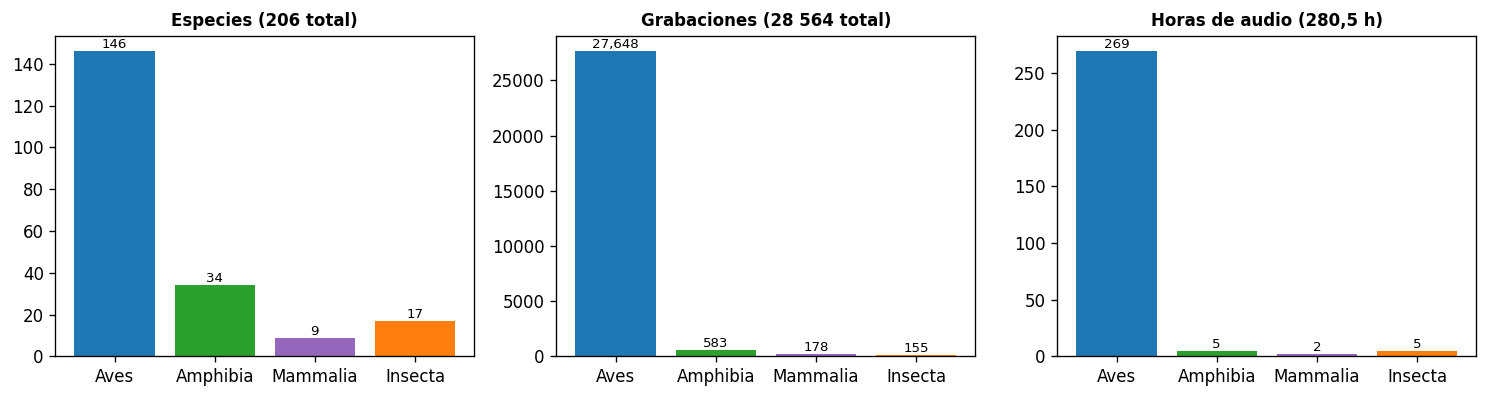

In [7]:
# ==============================================================================
# 2.2 VISUALIZACIÓN POR CLASE TAXONÓMICA (ESPECIES, GRABACIONES Y HORAS)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, col, title in zip(
    axes,
    ["n_especies", "n_grabaciones", "horas_audio"],
    ["Especies (206 total)", "Grabaciones (28 564 total)", "Horas de audio (280,5 h)"],
):
    vals = class_summary[col]
    # Dibujar barras coloreadas según CLASS_COLORS
    ax.bar(class_summary.index, vals, color=[CLASS_COLORS[c] for c in class_summary.index])
    ax.set_title(title, fontsize=10, fontweight="bold")
    # Escribir el valor exacto encima de cada barra
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_class_summary.png", dpi=130)
plt.show()

**Interpretación de las tablas por clase y colección:**
1. **Sesgo taxonómico extremo hacia `Aves`:** Aunque `Amphibia` (34 spp.), `Insecta` (17 spp.) y `Mammalia` (9 spp.) representan el 29,1 % del número de especies (60 de 206), **solo representan el 3,21 % de las grabaciones (916 archivos)** y tienen una **mediana de 5 a 6 grabaciones por especie**. Con 5–6 grabaciones es imposible armar 5 folds de validación cruzada más un conjunto de prueba independiente por autor.
2. **Diferencias estructurales entre colecciones:**
   - **Xeno-Canto (`XC`):** Aporta el 74,2 % de las grabaciones (21 204 clips, 230,9 h). Es la **única fuente que tiene calificaciones de calidad (`97,2 %` calificadas de 0,5 a 5,0)** y la **única que reporta etiquetas secundarias (`12,5 %`)**.
   - **iNaturalist (`iNat`):** Aporta el 25,2 % (7 198 clips, 44,3 h), con grabaciones más cortas (mediana 15,16 s), **sin calificaciones de calidad (`rating = 0.0` en el 100 %)** y **sin etiquetas secundarias anotadas (`0 %`)**.
   - **Instituto Humboldt (`CSA`):** Aporta 162 grabaciones colombianas largas (mediana 100,9 s, enfocadas sobre todo en insectos y anfibios locales), también con `rating = 0.0` y sin secundarias.

---
## 3. Análisis Detallado de Duraciones, Calificaciones (`rating`) y Tipos de Vocalización (`type`)

En el **Hito 2** todas las grabaciones del subconjunto se estandarizarán a 32 kHz mono, se filtrarán en banda y se **segmentarán en clips de 5 segundos**. Por ello necesitamos cuantificar:
- Cuántas grabaciones duran **menos de 1 segundo** (demasiado cortas, prácticamente sin contenido espectral útil $\to$ se excluirán).
- Cuántas grabaciones duran **entre 1 y 5 segundos** (requerirán *padding* en el Hito 2 para completar una ventana de 5 s).
- Cuántas grabaciones son **muy largas ($> 300\text{ s}$)**, las cuales generarían decenas de ventanas de 5 s de un mismo archivo y podrían contener largos silencios intermedios (*weak labels*).

In [8]:
# ==============================================================================
# 3.1 ESTADÍSTICOS DE DURACIÓN, DISTRIBUCIÓN DE RATING Y VOCABULARIO DE 'type'
# ==============================================================================
# Calcular percentiles detallados de la duración en segundos
dur_desc = df["duration_s"].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2)
print("Percentiles de duración (segundos) en las 28 564 grabaciones:")
print(dur_desc.to_string())

# Contabilizar grabaciones por rangos operativos relevantes para la segmentación de 5 s del Hito 2
print(f"\nGrabaciones < 1 s   (descartables por cortas) : {(df['duration_s'] < 1.0).sum():,} ({(df['duration_s'] < 1.0).mean()*100:.2f}%)")
print(f"Grabaciones < 5 s   (requieren padding a 5 s) : {(df['duration_s'] < 5.0).sum():,} ({(df['duration_s'] < 5.0).mean()*100:.2f}%)")
print(f"Grabaciones 5–60 s  (rango estándar de clips) : {df['duration_s'].between(5.0, 60.0).sum():,} ({df['duration_s'].between(5.0, 60.0).mean()*100:.2f}%)")
print(f"Grabaciones > 300 s (grabaciones de > 5 min)  : {(df['duration_s'] > 300.0).sum():,} ({(df['duration_s'] > 300.0).mean()*100:.2f}%)")

# Tabla cruzada entre colección y calificación 'rating'
print("\nTabla cruzada Colección vs Rating (obsérvese que 0.0 concentra todo iNat, CSA y 588 XC sin calificar):")
print(pd.crosstab(df["collection"], df["rating"]).to_string())

# Contar los 15 tipos de vocalización más frecuentes en la columna 'type'
top_types = pd.Series([t for ts in df["types"] for t in ts]).value_counts().head(15)
top_types.to_csv(TABLES_DIR / "top_types.csv", header=["count"])
print("\nTop 15 tipos de vocalización reportados:")
print(top_types.to_string())

Percentiles de duración (segundos) en las 28 564 grabaciones:
count    28564.00
mean        35.35
std         50.61
min          0.54
1%           1.99
5%           3.94
10%          5.62
25%         10.58
50%         20.98
75%         41.30
90%         76.09
95%        110.94
99%        232.31
max       1774.39

Grabaciones < 1 s   (descartables por cortas) : 24 (0.08%)
Grabaciones < 5 s   (requieren padding a 5 s) : 2,314 (8.10%)
Grabaciones 5–60 s  (rango estándar de clips) : 21,968 (76.91%)
Grabaciones > 300 s (grabaciones de > 5 min)  : 139 (0.49%)

Tabla cruzada Colección vs Rating (obsérvese que 0.0 concentra todo iNat, CSA y 588 XC sin calificar):
rating       0.0  0.5  1.0  1.5  2.0  2.5   3.0  3.5   4.0   4.5   5.0
collection                                                            
CSA          162    0    0    0    0    0     0    0     0     0     0
XC           588   26  228   70  752  360  2886  895  7582  1261  6556
iNat        7198    0    0    0    0    0     0    0

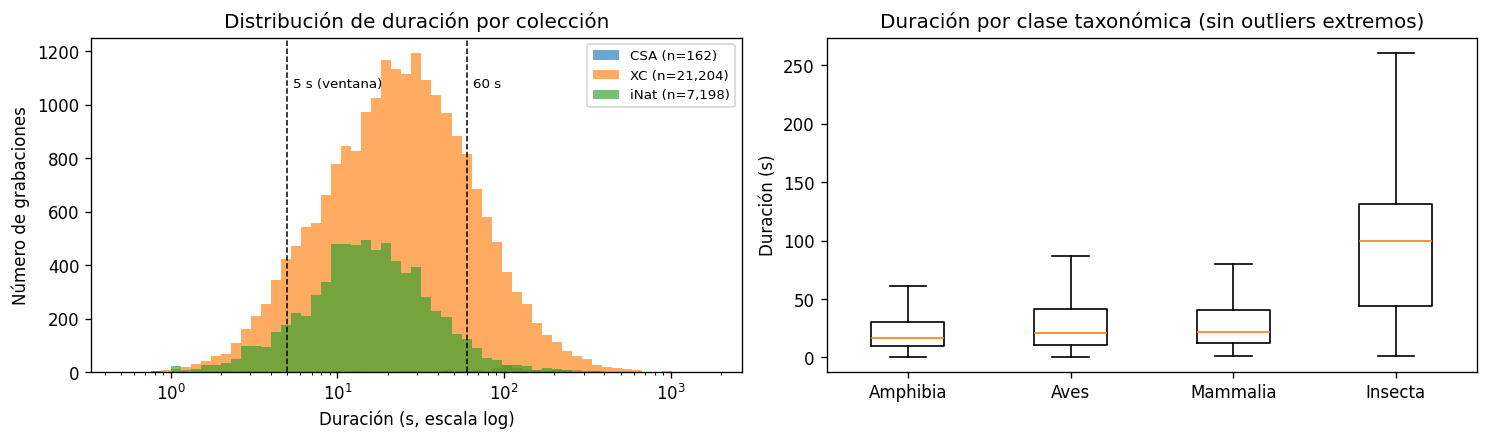

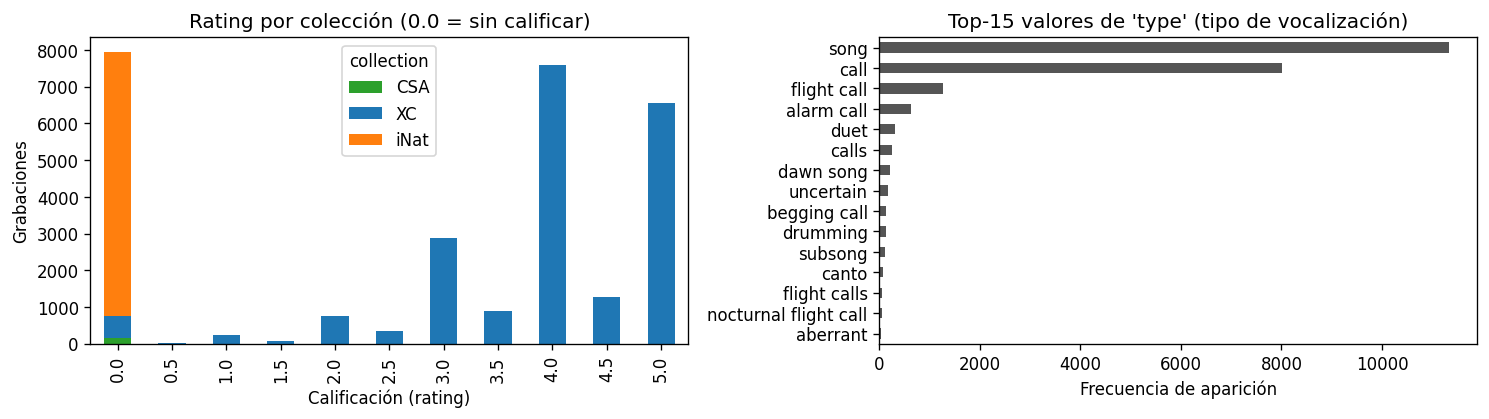

In [9]:
# ==============================================================================
# 3.2 GRÁFICAS DE DURACIÓN POR COLECCIÓN/CLASE, RATING Y TIPOS DE VOCALIZACIÓN
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))

# Panel izquierdo: histograma en escala logarítmica de la duración según colección
bins = np.logspace(np.log10(0.5), np.log10(df["duration_s"].max()), 60)
for coll, sub_c in df.groupby("collection"):
    axes[0].hist(sub_c["duration_s"], bins=bins, alpha=0.65, label=f"{coll} (n={len(sub_c):,})")
axes[0].set_xscale("log")
for x, lab in [(5, "5 s (ventana)"), (60, "60 s")]:
    axes[0].axvline(x, ls="--", c="k", lw=0.9)
    axes[0].text(x * 1.08, axes[0].get_ylim()[1] * 0.85, lab, fontsize=8)
axes[0].set_xlabel("Duración (s, escala log)")
axes[0].set_ylabel("Número de grabaciones")
axes[0].set_title("Distribución de duración por colección")
axes[0].legend(fontsize=8)

# Panel derecho: boxplot de duración por clase taxonómica (ocultando outliers para ver medianas y RIC)
order_cls = df.groupby("class_name")["duration_s"].median().sort_values().index
axes[1].boxplot([df.loc[df["class_name"] == c, "duration_s"] for c in order_cls], showfliers=False)
axes[1].set_xticks(range(1, len(order_cls) + 1), order_cls)
axes[1].set_ylabel("Duración (s)")
axes[1].set_title("Duración por clase taxonómica (sin outliers extremos)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_durations.png", dpi=130)
plt.show()

# Segunda figura: distribución de 'rating' y top-15 valores de 'type'
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
ct_r = pd.crosstab(df["rating"], df["collection"])
ct_r.plot.bar(stacked=True, ax=axes[0], color={"XC": "#1f77b4", "iNat": "#ff7f0e", "CSA": "#2ca02c"})
axes[0].set_title("Rating por colección (0.0 = sin calificar)")
axes[0].set_xlabel("Calificación (rating)")
axes[0].set_ylabel("Grabaciones")

top_types[::-1].plot.barh(ax=axes[1], color="#555555")
axes[1].set_title("Top-15 valores de 'type' (tipo de vocalización)")
axes[1].set_xlabel("Frecuencia de aparición")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_rating_and_types.png", dpi=130)
plt.show()

---
## 4. Tabla Maestra de las 206 Especies, Desbalance Global (Coeficiente de Gini) y Análisis de `train_soundscapes`

### 4.1 ¿De dónde sale la función `gini_coefficient(values)` y qué calcula `sp_summary`?

Para documentar rigurosamente el desbalance entre especies usamos dos indicadores complementarios:
1. **Razón de desbalance (`máximo / mínimo`):** divide el número de grabaciones de la especie más frecuente (`grekis` = 990) entre la menos frecuente (2 grabaciones), dando **495:1**. Es intuitiva, pero solo usa 2 de las 206 especies.
2. **Coeficiente de Gini (`gini_coefficient`):** mide la desigualdad acumulada considerando **las 206 especies simultáneamente** (el área entre la recta de equidad perfecta a $45^\circ$ y la curva de Lorenz de grabaciones acumuladas):
   - Primero se ordena el vector de conteos de menor a mayor: $x_{(1)} \le x_{(2)} \le \dots \le x_{(N)}$, donde $i \in \{1, 2, \dots, N\}$ es la posición (*rank*) de cada especie.
   - Luego se aplica la fórmula discreta de Gini:
     $$G = \frac{\sum_{i=1}^{N} (2i - N - 1)\, x_{(i)}}{N \sum_{i=1}^{N} x_{(i)}}$$
   - **¿Por qué aparece el peso $(2i - N - 1)$?** Porque a las especies con menos grabaciones ($i$ pequeño) les asigna pesos negativos y a las especies con más grabaciones ($i$ cercano a $N$) pesos positivos; si todas las especies tienen el mismo número de grabaciones $c$, la suma de $(2i - N - 1)$ da exactamente $0$ ($G = 0.0$, igualdad perfecta). Si una sola especie acapara casi todos los audios, $G \to 1.0$.

Estadísticos de grabaciones por especie (206 especies):
count    206.00
mean     138.66
std      169.18
min        2.00
25%       19.00
50%       80.50
75%      182.75
max      990.00

Ratio máx/mín global          : 495.0:1 (990 en 'grekis' vs 2)
Coeficiente de Gini global    : 0.590
Especies con < 20 grabaciones : 53 de 206 (25.7%)
Especies con < 10 grabaciones : 39 de 206 (18.9%)

Estadísticos de distancia geográfica a El Silencio (km) en las grabaciones con coordenadas:
count    27755.0
mean      2450.8
std       1919.8
min          1.0
25%        834.1
50%       2189.7
75%       3861.0
max      19788.1
Grabaciones a <= 300 km (regionales): 2,977 (10.42%)
Grabaciones dentro de Colombia      : 7,734 (27.08%)


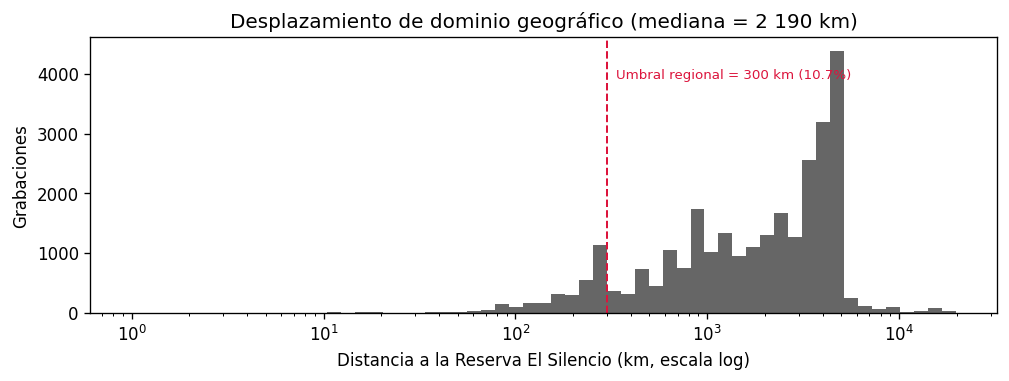

In [10]:
# ==============================================================================
# 4.1 AGREGACIÓN POR ESPECIE (206 ESPECIES) Y MÉTRICAS DE DESBALANCE GLOBAL
# ==============================================================================
def gini_coefficient(values: pd.Series | np.ndarray) -> float:
    """Calcula el coeficiente de Gini (0 = equilibrio perfecto, 1 = concentración total en una clase)."""
    x = np.sort(np.asarray(values, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return 0.0
    ranks = np.arange(1, n + 1, dtype=float)
    return float((2.0 * ranks - n - 1.0).dot(x) / (n * x.sum()))

# Calcular todas las métricas agregadas por especie sobre las 28 564 grabaciones
sp_summary = df.groupby("primary_label").agg(
    n_recordings=("filename", "size"),                                         # Total de grabaciones de la especie
    hours=("duration_s", lambda s: s.sum() / 3600.0),                          # Horas totales de audio de la especie
    median_dur_s=("duration_s", "median"),                                     # Duración mediana de sus clips (s)
    n_xc=("collection", lambda s: (s == "XC").sum()),                          # Grabaciones provenientes de Xeno-Canto
    n_inat=("collection", lambda s: (s == "iNat").sum()),                      # Grabaciones provenientes de iNaturalist
    n_csa=("collection", lambda s: (s == "CSA").sum()),                        # Grabaciones provenientes del Inst. Humboldt
    n_rating4=("rating", lambda s: (s >= 4.0).sum()),                          # Grabaciones de alta calidad (rating >= 4.0)
    mean_rating_rated=("rating", lambda s: s[s > 0].mean()),                   # Promedio de rating (excluyendo 0.0 = sin calificar)
    n_authors=("author", "nunique"),                                           # Número de recordistas distintos
    max_author_share=("author", lambda s: s.value_counts(normalize=True).iloc[0]), # % máximo concentrado en un solo autor
    n_regional=("regional", "sum"),                                            # Grabaciones a <= 300 km de El Silencio
    n_colombia=("colombia", "sum"),                                            # Grabaciones dentro de Colombia
    median_dist_km=("dist_km", "median"),                                      # Mediana de distancia a El Silencio (km)
    pct_with_secondary=("n_secondary", lambda s: (s > 0).mean() * 100.0),      # % de clips con etiquetas secundarias
)

# Añadir nombre científico, nombre común y clase taxonómica desde taxonomy.csv y ordenar de mayor a menor volumen
sp_summary = tax.set_index("primary_label")[["scientific_name", "common_name", "class_name"]].join(sp_summary)
sp_summary = sp_summary.sort_values("n_recordings", ascending=False)

print("Estadísticos de grabaciones por especie (206 especies):")
print(sp_summary["n_recordings"].describe().round(2).to_string())
print(f"\nRatio máx/mín global          : {sp_summary['n_recordings'].max() / sp_summary['n_recordings'].min():.1f}:1 ({sp_summary['n_recordings'].max()} en 'grekis' vs {sp_summary['n_recordings'].min()})")
print(f"Coeficiente de Gini global    : {gini_coefficient(sp_summary['n_recordings']):.3f}")
print(f"Especies con < 20 grabaciones : {(sp_summary['n_recordings'] < 20).sum()} de 206 ({(sp_summary['n_recordings'] < 20).mean()*100:.1f}%)")
print(f"Especies con < 10 grabaciones : {(sp_summary['n_recordings'] < 10).sum()} de 206 ({(sp_summary['n_recordings'] < 10).mean()*100:.1f}%)")

print("\nEstadísticos de distancia geográfica a El Silencio (km) en las grabaciones con coordenadas:")
print(df["dist_km"].describe().round(1).to_string())
print(f"Grabaciones a <= 300 km (regionales): {df['regional'].sum():,} ({df['regional'].mean()*100:.2f}%)")
print(f"Grabaciones dentro de Colombia      : {df['colombia'].sum():,} ({df['colombia'].mean()*100:.2f}%)")

# Graficar histograma logarítmico de distancias hacia la Reserva El Silencio
fig, ax = plt.subplots(figsize=(8.5, 3.3))
d_valid = df["dist_km"].dropna()
ax.hist(d_valid, bins=np.logspace(0, np.log10(d_valid.max()), 60), color="#666666")
ax.set_xscale("log")
ax.axvline(REGION_RADIUS_KM, color="crimson", ls="--", lw=1.2)
ax.text(REGION_RADIUS_KM * 1.12, ax.get_ylim()[1] * 0.85, f"Umbral regional = {int(REGION_RADIUS_KM)} km ({(d_valid <= REGION_RADIUS_KM).mean():.1%})", color="crimson", fontsize=8)
ax.set_xlabel("Distancia a la Reserva El Silencio (km, escala log)")
ax.set_ylabel("Grabaciones")
ax.set_title("Desplazamiento de dominio geográfico (mediana = 2 190 km)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_distance_to_site.png", dpi=130)
plt.show()

### 4.2 Inspección de los 9 726 Paisajes Sonoros Pasivos Locales (`train_soundscapes`)
En `src/data/raw/train_soundscapes/` se encuentran las grabaciones de monitoreo acústico pasivo (PAM) capturadas directamente en la Reserva *El Silencio*. Aunque no tienen etiquetas de especie, sus nombres de archivo siguen el patrón `<SITIO>_<AAAAMMDD>_<HHMMSS>.ogg` (por ejemplo, `H02_20230420_074000.ogg`).

En la siguiente celda extraemos con una expresión regular (`SOUNDSCAPE_NAME_RE`, también en [`src/utils/helpers.py`](../src/utils/helpers.py)) el sitio, la fecha y la hora de cada uno de los **9 726 archivos**, verificamos su duración e integridad OGG y analizamos su cobertura horaria y por grabadora.

Total archivos en train_soundscapes : 9,726 (162.1 horas)
Duración mínima / máxima (s)        : 60.0 s / 60.0 s (100% miden exactamente 60.0 s)
Sample rate / canales               : [32000] Hz / [1] canal (mono)
Sitios/grabadoras únicos            : 56 sitios (prefijos: {'H': 9206, 'O': 520})
Rango temporal de muestreo          : 2023-04-19 09:50:00 -> 2023-05-26 10:40:00 (38 días)
Porcentaje nocturno (18:00 a 06:00) : 49.5% (demuestra muestreo uniforme las 24 h en campo)


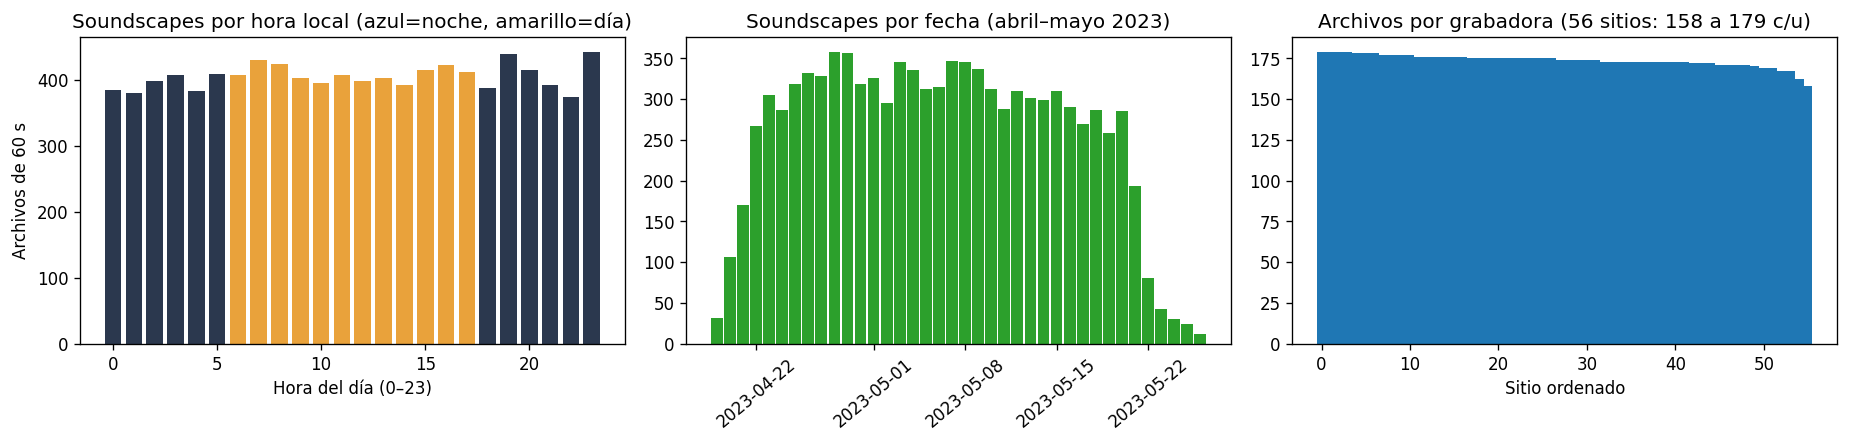

In [11]:
# ==============================================================================
# 4.2 ANÁLISIS COMPLETO DE train_soundscapes (9 726 PAISAJES SONOROS EN EL SILENCIO)
# ==============================================================================
# Expresión regular para descomponer <SITIO>_<AAAAMMDD>_<HHMMSS>.ogg
SOUNDSCAPE_NAME_RE = re.compile(r"^(?P<site>[A-Za-z0-9]+)_(?P<date>\d{8})_(?P<time>\d{6})\.ogg$")
ss_dir = RAW_DIR / "train_soundscapes"
ss_files = sorted(ss_dir.glob("*.ogg"))
ss_cache_path = PROCESSED_DIR / "train_soundscapes_meta.csv"

# Cargar desde caché en src/data/processed/ o construir leyendo los 9 726 archivos en paralelo
if ss_cache_path.is_file():
    ss_df = pd.read_csv(ss_cache_path)
    ss_df["datetime"] = pd.to_datetime(ss_df["datetime"])
else:
    parsed_names = [SOUNDSCAPE_NAME_RE.match(p.name).groupdict() for p in ss_files]
    with ThreadPoolExecutor(max_workers=16) as ex:
        ss_info = list(ex.map(ogg_header_info, ss_files))
    ss_df = pd.concat([pd.DataFrame(parsed_names), pd.DataFrame(ss_info)], axis=1)
    ss_df.insert(0, "filename", [p.name for p in ss_files])
    ss_df["datetime"] = pd.to_datetime(ss_df["date"] + ss_df["time"], format="%Y%m%d%H%M%S")
    ss_df["hour"] = ss_df["datetime"].dt.hour
    ss_df["day"] = ss_df["datetime"].dt.date.astype(str)
    ss_df["site_prefix"] = ss_df["site"].str.extract(r"^([A-Za-z]+)")[0]
    ss_df.to_csv(ss_cache_path, index=False)

# Calcular porcentaje de grabaciones nocturnas (entre 18:00 y 05:59)
pct_night = ((ss_df["hour"] >= 18) | (ss_df["hour"] < 6)).mean() * 100

print(f"Total archivos en train_soundscapes : {len(ss_df):,} ({ss_df['duration_s'].sum()/3600:.1f} horas)")
print(f"Duración mínima / máxima (s)        : {ss_df['duration_s'].min():.1f} s / {ss_df['duration_s'].max():.1f} s (100% miden exactamente 60.0 s)")
print(f"Sample rate / canales               : {ss_df['sample_rate'].unique().tolist()} Hz / {ss_df['channels'].unique().tolist()} canal (mono)")
print(f"Sitios/grabadoras únicos            : {ss_df['site'].nunique()} sitios (prefijos: {ss_df['site_prefix'].value_counts().to_dict()})")
print(f"Rango temporal de muestreo          : {ss_df['datetime'].min()} -> {ss_df['datetime'].max()} ({ss_df['day'].nunique()} días)")
print(f"Porcentaje nocturno (18:00 a 06:00) : {pct_night:.1f}% (demuestra muestreo uniforme las 24 h en campo)")

# Graficar distribución por hora del día, por fecha y por grabadora/sitio
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.8))
h_counts = ss_df["hour"].value_counts().sort_index()
axes[0].bar(h_counts.index, h_counts.values, color=["#2b384e" if (h >= 18 or h < 6) else "#e9a23b" for h in h_counts.index])
axes[0].set_title("Soundscapes por hora local (azul=noche, amarillo=día)")
axes[0].set_xlabel("Hora del día (0–23)")
axes[0].set_ylabel("Archivos de 60 s")

d_counts = ss_df.groupby(pd.to_datetime(ss_df["day"])).size()
axes[1].bar(d_counts.index, d_counts.values, width=0.9, color="tab:green")
axes[1].set_title("Soundscapes por fecha (abril–mayo 2023)")
axes[1].tick_params(axis="x", rotation=40)

s_counts = ss_df["site"].value_counts()
axes[2].bar(range(len(s_counts)), s_counts.values, color="tab:blue", width=1.0)
axes[2].set_title(f"Archivos por grabadora ({len(s_counts)} sitios: 158 a 179 c/u)")
axes[2].set_xlabel("Sitio ordenado")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_soundscapes_overview.png", dpi=130)
plt.show()

---
## 5. Selección y Justificación del Subconjunto de 16 Especies del Magdalena Medio

### 5.1 Embudo cuantitativo de elegibilidad por especie (Criterios E1–E5)
Las 206 especies del dataset fueron definidas por los organizadores de BirdCLEF+ 2025 e investigadores del Instituto Humboldt y la Fundación Biodiversa Colombia como especies presentes en la Reserva Natural *El Silencio* (Valle del Magdalena Medio). El objetivo de seleccionar de **10 a 20 especies** para el curso no es adivinar cuáles son del Magdalena Medio (todas lo son), sino **seleccionar un subconjunto ecológicamente representativo que posea soporte estadístico suficiente para entrenar y evaluar clasificadores supervisados (Baseline, SVM, Random Forest, XGBoost) sin fuga de datos**.

Definimos y aplicamos paso a paso en código los **5 criterios cuantitativos de elegibilidad (`E1`–`E5`)**:

| Código | Criterio | Condición en código | Justificación estadística y metodológica |
|---|---|---|---|
| **E1** | Clase taxonómica | `class_name == "Aves"` | Las clases no-aves tienen mediana de 5–6 grabaciones por especie; es imposible dividirlas en 5 folds + test agrupados por autor sin dejar particiones vacías. |
| **E2** | Volumen mínimo | `n_recordings >= 120` | Con ~14,3 % reservado para `test`, garantiza **al menos 20 grabaciones independientes de prueba** por especie y $\ge 100$ en los 5 folds de validación cruzada. |
| **E3** | Núcleo de calidad alta | `n_rating4 >= 60` | Exige al menos 60 grabaciones de Xeno-Canto con `rating >= 4.0` (alta relación señal-ruido) para que el clasificador disponga de patrones limpios. |
| **E4** | Diversidad de autores | `n_authors >= 40` | Garantiza al menos 40 recordistas distintos por especie, evitando que un único autor o micrófono monopolice la clase al agrupar por `author`. |
| **E5** | Evidencia regional | `n_regional >= 10` | Exige al menos 10 grabaciones tomadas a $\le 300\text{ km}$ de *El Silencio* para asegurar representación del dialecto y paisaje acústico regional. |

In [12]:
# ==============================================================================
# 5.1 APLICACIÓN PASO A PASO DEL EMBUDO DE ELEGIBILIDAD E1–E5 SOBRE LAS 206 ESPECIES
# ==============================================================================
ELIGIBILITY_CRITERIA = {
    "class_name": "Aves",
    "min_recordings": 120,
    "min_rating4": 60,
    "min_authors": 40,
    "min_regional": 10,
}

# Evaluar cada condición booleana de forma acumulativa para documentar cuántas especies pasan cada filtro
cond_e1 = sp_summary["class_name"] == ELIGIBILITY_CRITERIA["class_name"]
cond_e2 = cond_e1 & (sp_summary["n_recordings"] >= ELIGIBILITY_CRITERIA["min_recordings"])
cond_e3 = cond_e2 & (sp_summary["n_rating4"] >= ELIGIBILITY_CRITERIA["min_rating4"])
cond_e4 = cond_e3 & (sp_summary["n_authors"] >= ELIGIBILITY_CRITERIA["min_authors"])
cond_e5 = cond_e4 & (sp_summary["n_regional"] >= ELIGIBILITY_CRITERIA["min_regional"])

# Marcar en sp_summary las 57 especies que superan los 5 filtros simultáneamente
sp_summary["eligible"] = cond_e5

# Construir y exportar la tabla del embudo de selección
funnel_df = pd.DataFrame({
    "Paso_del_embudo": [
        "0. Total inicial de especies en BirdCLEF+ 2025",
        "1. E1: Clase Aves",
        f"2. E2: + >= {ELIGIBILITY_CRITERIA['min_recordings']} grabaciones totales",
        f"3. E3: + >= {ELIGIBILITY_CRITERIA['min_rating4']} grabaciones con rating >= 4.0",
        f"4. E4: + >= {ELIGIBILITY_CRITERIA['min_authors']} autores distintos",
        f"5. E5: + >= {ELIGIBILITY_CRITERIA['min_regional']} grabaciones regionales (<= 300 km)",
    ],
    "Especies_que_cumplen": [
        len(sp_summary),
        int(cond_e1.sum()),
        int(cond_e2.sum()),
        int(cond_e3.sum()),
        int(cond_e4.sum()),
        int(cond_e5.sum()),
    ],
})
funnel_df.to_csv(TABLES_DIR / "selection_funnel.csv", index=False)
print("Embudo cuantitativo de elegibilidad (E1 a E5):")
print(funnel_df.to_string(index=False))

# Mostrar las primeras 20 especies del pool de 57 elegibles ordenadas por evidencia regional (n_regional)
eligible_pool = sp_summary[sp_summary["eligible"]].sort_values("n_regional", ascending=False)
print(f"\nTop 20 de las {len(eligible_pool)} especies elegibles ordenadas por grabaciones regionales (<= 300 km):")
eligible_pool[["scientific_name", "common_name", "n_recordings", "hours", "n_rating4", "n_authors", "n_regional", "n_colombia"]].head(20).round(2)

Embudo cuantitativo de elegibilidad (E1 a E5):
                                  Paso_del_embudo  Especies_que_cumplen
   0. Total inicial de especies en BirdCLEF+ 2025                   206
                                1. E1: Clase Aves                   146
              2. E2: + >= 120 grabaciones totales                    75
     3. E3: + >= 60 grabaciones con rating >= 4.0                    73
                 4. E4: + >= 40 autores distintos                    73
5. E5: + >= 10 grabaciones regionales (<= 300 km)                    57

Top 20 de las 57 especies elegibles ordenadas por grabaciones regionales (<= 300 km):


,scientific_name,common_name,n_recordings,hours,n_rating4,n_authors,n_regional,n_colombia
primary_label,,,,,,,,
colcha1,Ortalis columbiana,Colombian Chachalaca,145,2.51,62,65,128,143
roahaw,Rupornis magnirostris,Roadside Hawk,709,7.80,371,293,104,212
wbwwre1,Henicorhina leucosticta,White-breasted Wood-Wren,499,5.30,363,140,74,236
grekis,Pitangus sulphuratus,Great Kiskadee,990,8.28,387,370,68,152
trsowl,Megascops choliba,Tropical Screech-Owl,470,5.68,193,230,63,133
soulap1,Vanellus chilensis,Southern Lapwing,487,3.21,225,230,63,125
trokin,Tyrannus melancholicus,Tropical Kingbird,787,6.91,351,305,62,125
bugtan,Thraupis episcopus,Blue-gray Tanager,280,2.23,147,119,53,115
compau,Nyctidromus albicollis,Common Pauraque,808,9.03,325,348,52,142


### 5.2 Reglas de Selección Curada (R1–R5) y las 16 Especies Definitivas
De las **57 especies elegibles**, seleccionamos **16 especies** (en el centro del rango de 10 a 20 pedido por la guía del curso) aplicando cinco reglas ecológicas y de diseño experimental:
1. **R1 — Diversidad taxonómica:** máximo **2 especies por familia** (logramos **14 familias** y **11 órdenes** taxonómicos distintos).
2. **R2 — Cobertura de gremios horarios (24 h) y estratos de hábitat:** dado que el 49,5 % de `train_soundscapes` es nocturno, incluimos **2 especies nocturnas** (`trsowl`, `compau`), **4 crepusculares o mixtas** (`littin1`, `gycwor1`, `laufal1`, `soulap1`) y **10 diurnas**, cubriendo suelo de bosque húmedo, sotobosque, dosel, borde ribereño, ciénagas y potreros ganaderos.
3. **R3 — Especie endémica / emblemática regional:** incluimos a ***Ortalis columbiana* (`colcha1`, Guacharaca Colombiana)**, especie **endémica de Colombia** (valles interandinos del Magdalena y Cauca) donde el **88,3 % de todas sus grabaciones (128 de 145)** proviene directamente del radio regional de $300\text{ km}$.
4. **R4 — Cuatro pares acústicamente confundibles (para poner a prueba los descriptores MFCC y espectrales en los Hitos 3–6):**
   - **Par 1 (`grekis` $\leftrightarrow$ `rumfly1`):** dos atrapamoscas Tyrannidae simpátricos con vocalizaciones tipo *kiskadee* muy parecidas.
   - **Par 2 (`bugtan` $\leftrightarrow$ `paltan1`):** dos tangaras del mismo género (*Thraupis*) que comparten bordes y palmas con cantos agudos chirriantes.
   - **Par 3 (`colcha1` $\leftrightarrow$ `gycwor1`):** dos especies de gran tamaño que emiten coros colectivos potentes y ruidosos al amanecer y al ocaso.
   - **Par 4 (`trsowl` $\leftrightarrow$ `compau`):** búho y chotacabras nocturnos que cantan simultáneamente en las mismas horas de la noche.
5. **R5 — Prioridad por evidencia regional:** ante igualdad de gremio o familia, se eligieron las especies con mayor número de grabaciones regionales (`n_regional`).

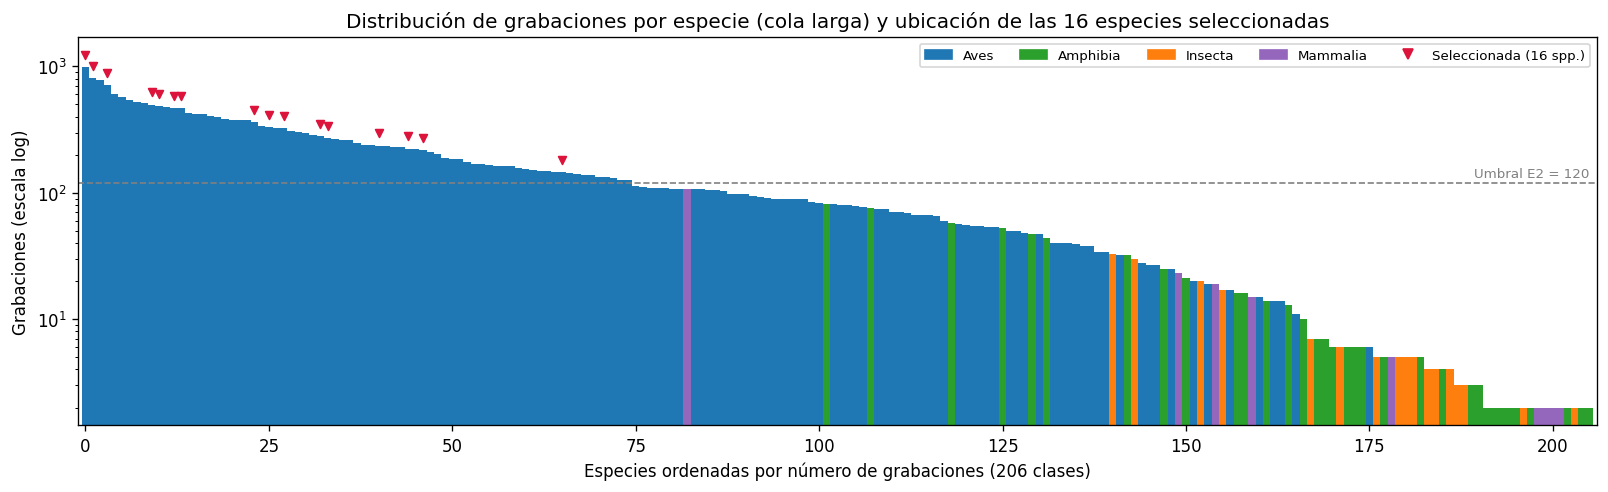

In [13]:
# ==============================================================================
# 5.2 DEFINICIÓN EXPLÍCITA DE LAS 16 ESPECIES SELECCIONADAS Y GRÁFICA DE COLA LARGA
# ==============================================================================
# Cada tupla contiene: (primary_label, familia, orden, actividad_horaria, hábitat_gremio, justificación)
SUBSET_DEFINITION = [
    ("colcha1", "Cracidae", "Galliformes", "diurna", "borde de bosque / bosque secundario",
     "Endémica de Colombia (valles del Magdalena y Cauca); especie emblemática regional con la mayor proporción de grabaciones locales (128/145 a <=300 km). Coros ruidosos al amanecer."),
    ("littin1", "Tinamidae", "Tinamiformes", "crepuscular", "suelo de bosque",
     "Silbidos tonales ascendentes del sotobosque; activa al alba/ocaso, representa el estrato terrestre del bosque."),
    ("wbwwre1", "Troglodytidae", "Passeriformes", "diurna", "sotobosque de bosque húmedo",
     "Canto frecuente en bosque húmedo de tierras bajas; 2.ª especie con más grabaciones regionales (74). Indicador de bosque."),
    ("chbant1", "Thamnophilidae", "Passeriformes", "diurna", "sotobosque de bosque húmedo",
     "Hormiguero de interior de bosque, sensible a fragmentación; aporta un gremio insectívoro de sotobosque."),
    ("linwoo1", "Picidae", "Piciformes", "diurna", "borde de bosque",
     "Incluye tamborileo (sonido no vocal, 'drumming') además de llamadas: diversidad de tipo de señal."),
    ("orcpar", "Psittacidae", "Psittaciformes", "diurna", "dosel / áreas abiertas",
     "Llamadas de bandada de banda ancha y alta tasa de repetición; gremio frugívoro/granívoro de dosel."),
    ("bugtan", "Thraupidae", "Passeriformes", "diurna", "dosel / borde",
     "Tangara común de borde. Par confundible con Palm Tanager (cantos chirriantes muy similares)."),
    ("paltan1", "Thraupidae", "Passeriformes", "diurna", "dosel / palmas / borde",
     "Par confundible con Blue-gray Tanager; permite medir discriminación fina intra-familia."),
    ("grekis", "Tyrannidae", "Passeriformes", "diurna", "áreas abiertas / borde / riberas",
     "Especie más grabada del dataset (990); muy común en el Magdalena Medio. Par confundible con Rusty-margined Flycatcher."),
    ("rumfly1", "Tyrannidae", "Passeriformes", "diurna", "borde cerca de agua",
     "Plumaje y vocalizaciones semejantes a Great Kiskadee ('kiskadee-like'); alta evidencia regional (48)."),
    ("roahaw", "Accipitridae", "Accipitriformes", "diurna", "borde / áreas abiertas",
     "Rapaz más común; mayor número de grabaciones regionales (104). Llamadas largas descendentes."),
    ("laufal1", "Falconidae", "Falconiformes", "crepuscular/diurna", "borde de bosque",
     "Rapaz con duetos largos y estereotipados, audibles a gran distancia; 7 h de audio."),
    ("soulap1", "Charadriidae", "Charadriiformes", "diurna/nocturna", "potreros / orillas de ciénaga",
     "Representa el paisaje ganadero y humedales (ciénagas) del Magdalena Medio; llama también de noche."),
    ("gycwor1", "Rallidae", "Gruiformes", "crepuscular", "humedales / bosque ribereño",
     "Coros fuertes al alba/ocaso en humedales; par confundible con los coros de Colombian Chachalaca."),
    ("trsowl", "Strigidae", "Strigiformes", "nocturna", "borde / áreas abiertas",
     "Gremio nocturno (los paisajes sonoros cubren 24 h). Trino corto; par confundible con Common Pauraque."),
    ("compau", "Caprimulgidae", "Caprimulgiformes", "nocturna", "áreas abiertas / borde",
     "Chotacabras nocturno muy común; silbido característico. Completa el gremio nocturno."),
]

# Extraer lista ordenada y conjunto de los 16 códigos seleccionados
SUBSET_CODES = [row[0] for row in SUBSET_DEFINITION]
SUBSET_SET = set(SUBSET_CODES)
sp_summary["selected"] = sp_summary.index.isin(SUBSET_SET)

# Comprobar con assert que ninguna de las 16 especies viola E1–E5 ni el rango de 10 a 20 especies
assert 10 <= len(SUBSET_CODES) <= 20, "El número de especies debe estar entre 10 y 20"
assert sp_summary.loc[SUBSET_CODES, "eligible"].all(), "Error: alguna especie seleccionada no cumple E1-E5"

# Guardar las tablas de resumen de las 206 especies y de las 57 elegibles
sp_summary.round(3).to_csv(TABLES_DIR / "species_summary_all.csv", encoding="utf-8")
sp_summary[sp_summary["eligible"]].round(3).to_csv(TABLES_DIR / "eligible_pool.csv", encoding="utf-8")

# Graficar la curva de cola larga de las 206 especies señalando con triángulos rojos las 16 seleccionadas
fig, ax = plt.subplots(figsize=(13.5, 4.2))
colors = sp_summary["class_name"].map(CLASS_COLORS)
ax.bar(range(len(sp_summary)), sp_summary["n_recordings"], color=colors, width=1.0)
sel_pos = np.where(sp_summary["selected"].values)[0]
ax.scatter(sel_pos, sp_summary["n_recordings"].values[sel_pos] * 1.25, marker="v", color="crimson", s=22, zorder=3)
ax.set_yscale("log")
ax.set_xlabel("Especies ordenadas por número de grabaciones (206 clases)")
ax.set_ylabel("Grabaciones (escala log)")
ax.set_title("Distribución de grabaciones por especie (cola larga) y ubicación de las 16 especies seleccionadas")
ax.axhline(ELIGIBILITY_CRITERIA["min_recordings"], ls="--", c="gray", lw=1)
ax.text(len(sp_summary) - 1, ELIGIBILITY_CRITERIA["min_recordings"] * 1.1, f"Umbral E2 = {ELIGIBILITY_CRITERIA['min_recordings']}", ha="right", fontsize=8, color="gray")
handles = [Patch(color=col, label=c) for c, col in CLASS_COLORS.items()]
handles.append(Line2D([], [], marker="v", color="crimson", ls="", label="Seleccionada (16 spp.)"))
ax.legend(handles=handles, ncol=5, fontsize=8)
ax.set_xlim(-1, len(sp_summary))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_recordings_per_species.png", dpi=130)
plt.show()

---
## 6. Particionamiento Estratificado Agrupado (`StratifiedGroupKFold`) y Filtrado de Grabaciones (I1–I5)

### 6.1 Algoritmo de particionamiento sin fuga de información (*Zero Data Leakage*)
En [`docs/plan_trabajo.md`](../docs/plan_trabajo.md) se establece como criterio de aceptación obligatorio:
> *"Mantener particiones estratificadas fijas de entrenamiento, validación y prueba; evitar que segmentos de una misma grabación aparezcan en más de una partición."*

Si partiéramos después de segmentar en clips de 5 s con un `train_test_split` simple, dos ventanas consecutivas de la misma grabación caerían en entrenamiento y prueba, inflando artificialmente las métricas. Más aún: si dos grabaciones del mismo recordista (`author`) hechas el mismo día en el mismo punto caen en distintas particiones, el modelo memoriza la respuesta en frecuencia del micrófono y el ruido de fondo del autor.

Por eso realizamos la partición **a nivel de grabación y agrupando por `author`** mediante dos etapas de `StratifiedGroupKFold` con semilla fija (`SEED = 42`):
1. **Etapa externa (`outer_cv`, `n_splits=7`):** Divide todo el dataset separando `1/7` ($\approx 14,3\%$) como conjunto **`test` (hold-out final)** y dejando `6/7` ($\approx 85,7\%$) para desarrollo (`dev_idx`).
2. **Etapa interna (`inner_cv`, `n_splits=5`):** Divide el conjunto de desarrollo (`dev_idx`) en **5 folds balanceados (`fold0`, `fold1`, `fold2`, `fold3`, `fold4`)**, cada uno con $\approx 17,1\%$ de las grabaciones.
3. **Herencia hacia el Hito 2:** Cuando en el Hito 2 cada grabación se corte en segmentos de 5 segundos, **todos los segmentos de una grabación heredarán exactamente el valor de la columna `split` de su grabación madre**, garantizando matemáticamente cero fuga entre folds y test.

In [14]:
# ==============================================================================
# 6.1 CÓDIGO EXPLÍCITO DE PARTICIONAMIENTO (StratifiedGroupKFold AGRUPADO POR AUTOR)
# ==============================================================================
# Variable de estratificación 'y_strat': código de especie si pertenece a las 16 del subconjunto,
# o '__other__' si pertenece a las otras 190 especies (útil para pruebas open-set)
y_strat = df["primary_label"].where(df["primary_label"].isin(SUBSET_SET), "__other__").values

# Variable de agrupación 'groups_author': nombre del recordista (autor de la grabación)
# Como cada grabación tiene un único autor, agrupar por autor agrupa automáticamente por grabación y por sesión
groups_author = df["author"].fillna("unknown").values

# Inicializar la serie vacía donde guardaremos la etiqueta de partición ('test', 'fold0', ..., 'fold4')
split_col = pd.Series("", index=df.index, dtype=object)

# ETAPA 1 (Externa): Separar ~1/7 (14.3%) como conjunto de prueba 'test' (hold-out intocable hasta el final)
outer_cv = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer_cv.split(df, y_strat, groups_author))
split_col.iloc[test_idx] = "test"

# ETAPA 2 (Interna): Dividir el ~6/7 restante (dev_idx) en 5 folds estratificados y agrupados por autor
inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold_num, (_, val_pos) in enumerate(inner_cv.split(dev_idx, y_strat[dev_idx], groups_author[dev_idx])):
    # 'val_pos' son posiciones relativas a 'dev_idx'; las mapeamos a los índices reales de 'df'
    split_col.iloc[dev_idx[val_pos]] = f"fold{fold_num}"

# Asignar la columna 'split' al DataFrame general y exportar el mapeo completo de las 28 564 grabaciones
df["split"] = split_col
df[["filename", "primary_label", "author", "split"]].to_csv(PROCESSED_DIR / "split_all_recordings.csv", index=False)

print("Distribución de 'split' en las 28 564 grabaciones totales de train.csv:")
print(df["split"].value_counts().sort_index().to_string())

Distribución de 'split' en las 28 564 grabaciones totales de train.csv:
split
fold0    4897
fold1    4896
fold2    4897
fold3    4896
fold4    4896
test     4082


### 6.2 Aplicación explícita de los Criterios de Inclusión de Grabaciones (I1–I5)
Una vez asignada la partición, filtramos las grabaciones del subconjunto de 16 especies aplicando paso a paso las 5 reglas de control de calidad de grabaciones:
- **I1 (Pertenencia al subconjunto):** `primary_label` está en `SUBSET_SET` (selecciona **6 821 grabaciones candidatas**).
- **I2 (Duración mínima $\ge 1,0\text{ s}$):** descartamos los clips con `duration_s < 1.0` segundo (**4 grabaciones excluidas**), ya que un fragmento sub-segundo es insuficiente incluso aplicando *padding*. Los clips entre $1,0\text{ s}$ y $5,0\text{ s}$ sí se conservan y se rellenarán (*padding*) a $5,0\text{ s}$ en el Hito 2.
- **I3 (Calidad mínima en Xeno-Canto):** en `XC`, las calificaciones `0.5`, `1.0` y `1.5` identifican grabaciones con ruido extremo o señal apenas perceptible; las descartamos (**57 grabaciones excluidas**). Conservamos todas las de `rating >= 2.0` y todas las no calificadas (`rating == 0.0`).
- **I4 (Deduplicación de URLs idénticas):** si dos filas del subconjunto apuntan a la misma `url` de audio (`https://static.inaturalist.org/sounds/586116.mp3`, que aparece en `grekis/iNat586116.ogg` y `roahaw/iNat586116.ogg`), unificamos sus etiquetas en `labels_list` y eliminamos la fila duplicada (**1 duplicado fusionado**).
- **I5 (Etiquetas multietiqueta dentro del subconjunto):** construimos la columna `labels` uniendo `primary_label` con cualquier etiqueta de `secondary` que pertenezca a las 16 especies.

In [15]:
# ==============================================================================
# 6.2 APLICACIÓN EXPLÍCITA DE LOS CRITERIOS I1–I5 Y EXPORTACIÓN DE subset_recordings.csv
# ==============================================================================
MIN_DURATION_S = 1.0   # Umbral I2: mínimo 1.0 segundo de duración
MIN_XC_RATING = 2.0    # Umbral I3: mínimo rating 2.0 cuando la grabación está calificada en XC

# Criterio I1: Conservar únicamente grabaciones cuya etiqueta primaria esté en las 16 especies
sub = df[df["primary_label"].isin(SUBSET_SET)].copy()
n_initial = len(sub)

# Criterio I2: Identificar grabaciones de menos de 1.0 segundo
mask_lt1s = sub["duration_s"] < MIN_DURATION_S
n_excl_lt1s = int(mask_lt1s.sum())

# Criterio I3: Identificar grabaciones de XC con rating muy bajo (entre 0.5 y 1.5; rating 0.0 se conserva)
mask_low_xc = (sub["collection"] == "XC") & sub["rating"].between(0.1, MIN_XC_RATING - 0.01)
n_excl_low_xc = int(mask_low_xc.sum())

# Aplicar los filtros I2 e I3
sub = sub[~mask_lt1s & ~mask_low_xc].copy()

# Criterio I5: Construir la lista de etiquetas del subconjunto presentes en el audio (primaria U secundarias del subconjunto)
sub["labels_list"] = sub.apply(
    lambda r: sorted({r["primary_label"]} | {s for s in r["secondary"] if s in SUBSET_SET}),
    axis=1,
)

# Criterio I4: Detectar URLs repetidas dentro del subconjunto, fusionar sus etiquetas y eliminar la copia redundante
url_primary_sets = sub.groupby("url")["primary_label"].apply(set)
dup_urls_in_sub = url_primary_sets[url_primary_sets.str.len() > 1]
for url, prim_labs in dup_urls_in_sub.items():
    idx = sub.index[sub["url"] == url]
    merged_labels = sorted(set().union(*[set(sub.at[i, "labels_list"]) for i in idx]) | prim_labs)
    for i in idx:
        sub.at[i, "labels_list"] = merged_labels

drop_dup_mask = sub["url"].duplicated(keep="first")
n_merged_dups = int(drop_dup_mask.sum())
sub = sub[~drop_dup_mask].copy()
sub["n_labels"] = sub["labels_list"].str.len()

print(f"I1 Candidatas iniciales (16 especies)        : {n_initial:,}")
print(f"I2 Excluidas por duración < 1.0 s            : -{n_excl_lt1s}")
print(f"I3 Excluidas por XC rating entre 0.5 y 1.5   : -{n_excl_low_xc}")
print(f"I4 Duplicados de URL fusionados (iNat586116) : -{n_merged_dups}")
print(f"TOTAL GRABACIONES INCLUIDAS (subconjunto)    : {len(sub):,} ({sub['duration_s'].sum()/3600:.2f} horas)")

# Preparar y exportar la tabla limpia de grabaciones a src/data/processed/subset_recordings.csv
sub_export = sub[[
    "filename", "primary_label", "labels_list", "secondary", "collection", "rating",
    "duration_s", "author", "latitude", "longitude", "dist_km", "regional",
    "split", "url", "license",
]].copy()
sub_export["labels"] = sub_export.pop("labels_list").apply(" ".join)
sub_export["secondary"] = sub_export["secondary"].apply(" ".join)
cols_order = [
    "filename", "primary_label", "labels", "secondary", "collection", "rating",
    "duration_s", "author", "latitude", "longitude", "dist_km", "regional", "split", "url", "license",
]
sub_export = sub_export[cols_order]
sub_export.to_csv(PROCESSED_DIR / "subset_recordings.csv", index=False)
sub_export.head(5)

I1 Candidatas iniciales (16 especies)        : 6,821
I2 Excluidas por duración < 1.0 s            : -4
I3 Excluidas por XC rating entre 0.5 y 1.5   : -57
I4 Duplicados de URL fusionados (iNat586116) : -1
TOTAL GRABACIONES INCLUIDAS (subconjunto)    : 6,759 (71.40 horas)


,filename,primary_label,labels,secondary,collection,rating,duration_s,author,latitude,longitude,dist_km,regional,split,url,license
5652,bugtan/XC112883.ogg,bugtan,bugtan,,XC,5.0,6.164906,Sander Bot,9.1199,-79.6991,658.960759,False,fold4,https://xeno-canto.org/112883,cc-by-nc-sa 3.0
5653,bugtan/XC118988.ogg,bugtan,bugtan,,XC,3.0,12.042438,GABRIEL LEITE,-6.1802,-50.2968,3018.353652,False,fold4,https://xeno-canto.org/118988,cc-by-nc-sa 3.0
5654,bugtan/XC119223.ogg,bugtan,bugtan,,XC,4.0,16.326531,GABRIEL LEITE,-3.0843,-59.9950,1920.387194,False,fold4,https://xeno-canto.org/119223,cc-by-nc-sa 3.0
5655,bugtan/XC119815.ogg,bugtan,bugtan,,XC,4.0,24.058781,GABRIEL LEITE,-6.1924,-50.2020,3028.240948,False,fold4,https://xeno-canto.org/119815,cc-by-nc-sa 3.0
5656,bugtan/XC120827.ogg,bugtan,bugtan rumfly1,rumfly1,XC,4.5,18.364094,Lars Lachmann,0.4720,-79.2139,892.701776,False,fold1,https://xeno-canto.org/120827,cc-by-nc-sa 3.0


### 6.3 Verificación Automática de Cero Fuga de Información (*Zero Data Leakage*) y Tabla Maestra `subset_species.csv`
En la celda siguiente ejecutamos una prueba formal con `assert` comparando todos los pares posibles de particiones `(s1, s2)` entre `fold0`, `fold1`, `fold2`, `fold3`, `fold4` y `test` para verificar que:
- La intersección de **autores (`author`)** entre cualquier par de particiones es exactamente `0`.
- La intersección de **archivos (`filename`)** entre cualquier par de particiones es exactamente `0`.
- La intersección de **URLs (`url`)** entre cualquier par de particiones es exactamente `0`.

Además, calculamos para cada una de las 16 especies el peso inverso a su frecuencia (`weight_inv_freq`), que sirve como referencia directa para `class_weight="balanced"` en SVM y modelos de ensamble:
$$w_c = \frac{N_{\text{total}}}{16 \cdot N_c}$$

In [16]:
# ==============================================================================
# 6.3 PRUEBA AUTOMÁTICA DE CERO FUGA ENTRE PARTICIONES Y TABLA subset_species.csv
# ==============================================================================
split_names = sorted(sub["split"].unique())
for i, s1 in enumerate(split_names):
    sub1 = sub[sub["split"] == s1]
    for s2 in split_names[i + 1:]:
        sub2 = sub[sub["split"] == s2]
        # Comprobar intersección vacía de autores, nombres de archivo y URLs
        assert len(set(sub1["author"]) & set(sub2["author"])) == 0, f"Fuga de autor entre {s1} y {s2}"
        assert len(set(sub1["filename"]) & set(sub2["filename"])) == 0, f"Fuga de filename entre {s1} y {s2}"
        assert len(set(sub1["url"]) & set(sub2["url"])) == 0, f"Fuga de URL entre {s1} y {s2}"

print("VERIFICACIÓN EXITOSA: 0 autores, 0 archivos y 0 URLs compartidas entre fold0..fold4 y test.")

# Construir la tabla maestra de las 16 especies (sp_sel) uniendo metadatos ecológicos, conteos incluidos y conteos por split
meta_def_df = pd.DataFrame(
    SUBSET_DEFINITION,
    columns=["primary_label", "family", "order", "activity", "habitat", "rationale"],
).set_index("primary_label")

inc_stats = sub.groupby("primary_label").agg(
    n_incl=("filename", "size"),
    hours_incl=("duration_s", lambda s: s.sum() / 3600.0),
    n_regional_incl=("regional", "sum"),
    n_authors_incl=("author", "nunique"),
)
split_crosstab = pd.crosstab(sub["primary_label"], sub["split"])[["fold0", "fold1", "fold2", "fold3", "fold4", "test"]]

sp_sel = sp_summary.loc[SUBSET_CODES].join(meta_def_df).join(inc_stats).join(split_crosstab)
# Peso inversamente proporcional a la frecuencia de la especie: N_total / (16 * N_especie)
sp_sel["weight_inv_freq"] = (sp_sel["n_incl"].sum() / (len(sp_sel) * sp_sel["n_incl"])).round(3)
sp_sel.to_csv(PROCESSED_DIR / "subset_species.csv", encoding="utf-8")

print(f"\nRatio de desbalance en el subconjunto : {sp_sel['n_incl'].max() / sp_sel['n_incl'].min():.2f}:1 ({sp_sel['n_incl'].max()} en 'grekis' vs {sp_sel['n_incl'].min()} en 'colcha1')")
print(f"Coeficiente de Gini en el subconjunto : {gini_coefficient(sp_sel['n_incl']):.3f} (frente a 0.590 en las 206 especies)")
print(f"Mínimo de grabaciones en TEST por esp.: {sp_sel['test'].min()} grabaciones (en colcha1)")
print(f"Total en desarrollo (fold0..fold4)    : {sp_sel[['fold0','fold1','fold2','fold3','fold4']].values.sum():,} grabaciones (85.7%)")
print(f"Total en prueba (test hold-out)       : {sp_sel['test'].sum():,} grabaciones (14.3%)")

sp_sel[[
    "scientific_name", "common_name", "family", "activity",
    "n_incl", "hours_incl", "n_rating4", "n_authors_incl", "n_regional_incl",
    "fold0", "fold1", "fold2", "fold3", "fold4", "test", "weight_inv_freq",
]].round(2)

VERIFICACIÓN EXITOSA: 0 autores, 0 archivos y 0 URLs compartidas entre fold0..fold4 y test.

Ratio de desbalance en el subconjunto : 6.77:1 (982 en 'grekis' vs 145 en 'colcha1')
Coeficiente de Gini en el subconjunto : 0.284 (frente a 0.590 en las 206 especies)
Mínimo de grabaciones en TEST por esp.: 20 grabaciones (en colcha1)
Total en desarrollo (fold0..fold4)    : 5,794 grabaciones (85.7%)
Total en prueba (test hold-out)       : 965 grabaciones (14.3%)


,scientific_name,common_name,family,activity,n_incl,hours_incl,n_rating4,n_authors_incl,n_regional_incl,fold0,fold1,fold2,fold3,fold4,test,weight_inv_freq
primary_label,,,,,,,,,,,,,,,,
colcha1,Ortalis columbiana,Colombian Chachalaca,Cracidae,diurna,145,2.51,62,65,128,25,25,25,25,25,20,2.91
littin1,Crypturellus soui,Little Tinamou,Tinamidae,crepuscular,314,3.63,197,144,39,53,55,54,54,55,43,1.34
wbwwre1,Henicorhina leucosticta,White-breasted Wood-Wren,Troglodytidae,diurna,497,5.27,363,140,74,85,86,86,85,85,70,0.85
chbant1,Poliocrania exsul,Chestnut-backed Antbird,Thamnophilidae,diurna,270,3.19,171,108,24,47,46,46,47,46,38,1.56
linwoo1,Dryocopus lineatus,Lineated Woodpecker,Picidae,diurna,328,2.74,193,144,30,56,57,56,57,56,46,1.29
orcpar,Brotogeris jugularis,Orange-chinned Parakeet,Psittacidae,diurna,215,1.89,89,104,42,38,35,37,36,38,31,1.96
bugtan,Thraupis episcopus,Blue-gray Tanager,Thraupidae,diurna,273,2.18,147,118,53,45,48,47,47,47,39,1.55
paltan1,Thraupis palmarum,Palm Tanager,Thraupidae,diurna,224,2.28,129,98,33,38,38,38,38,37,35,1.89
grekis,Pitangus sulphuratus,Great Kiskadee,Tyrannidae,diurna,982,8.19,387,367,67,170,168,170,167,170,137,0.43


### 6.4 Tabla de Justificación Ecológica y Acústica de las 16 Especies Definitivas
Mostramos la tabla descriptiva completa con familia, orden, actividad horaria, hábitat y justificación individual de cada una de las 16 especies seleccionadas.

In [17]:
# ==============================================================================
# 6.4 TABLA DE JUSTIFICACIÓN DETALLADA POR ESPECIE
# ==============================================================================
sp_sel[["scientific_name", "common_name", "family", "order", "activity", "habitat", "n_incl", "n_regional_incl", "rationale"]]

,scientific_name,common_name,family,order,activity,habitat,n_incl,n_regional_incl,rationale
primary_label,,,,,,,,,
colcha1,Ortalis columbiana,Colombian Chachalaca,Cracidae,Galliformes,diurna,borde de bosque / bosque secundario,145,128,Endémica de Colombia (valles del Magdalena y Cauca); especie emblemática regional con la mayor proporción de grabaciones locales (128/145 a <=300 km). Coros ruidosos al amanecer.
littin1,Crypturellus soui,Little Tinamou,Tinamidae,Tinamiformes,crepuscular,suelo de bosque,314,39,"Silbidos tonales ascendentes del sotobosque; activa al alba/ocaso, representa el estrato terrestre del bosque."
wbwwre1,Henicorhina leucosticta,White-breasted Wood-Wren,Troglodytidae,Passeriformes,diurna,sotobosque de bosque húmedo,497,74,Canto frecuente en bosque húmedo de tierras bajas; 2.ª especie con más grabaciones regionales (74). Indicador de bosque.
chbant1,Poliocrania exsul,Chestnut-backed Antbird,Thamnophilidae,Passeriformes,diurna,sotobosque de bosque húmedo,270,24,"Hormiguero de interior de bosque, sensible a fragmentación; aporta un gremio insectívoro de sotobosque."
linwoo1,Dryocopus lineatus,Lineated Woodpecker,Picidae,Piciformes,diurna,borde de bosque,328,30,"Incluye tamborileo (sonido no vocal, 'drumming') además de llamadas: diversidad de tipo de señal."
orcpar,Brotogeris jugularis,Orange-chinned Parakeet,Psittacidae,Psittaciformes,diurna,dosel / áreas abiertas,215,42,Llamadas de bandada de banda ancha y alta tasa de repetición; gremio frugívoro/granívoro de dosel.
bugtan,Thraupis episcopus,Blue-gray Tanager,Thraupidae,Passeriformes,diurna,dosel / borde,273,53,Tangara común de borde. Par confundible con Palm Tanager (cantos chirriantes muy similares).
paltan1,Thraupis palmarum,Palm Tanager,Thraupidae,Passeriformes,diurna,dosel / palmas / borde,224,33,Par confundible con Blue-gray Tanager; permite medir discriminación fina intra-familia.
grekis,Pitangus sulphuratus,Great Kiskadee,Tyrannidae,Passeriformes,diurna,áreas abiertas / borde / riberas,982,67,Especie más grabada del dataset (990); muy común en el Magdalena Medio. Par confundible con Rusty-margined Flycatcher.


---
## 7. Visualizaciones del Subconjunto: Distribución, Desbalance, Geografía, Particiones y Co-ocurrencia

En las dos celdas siguientes generamos y comentamos línea por línea las gráficas clave del subconjunto definitivo:
1. **Grabaciones incluidas, horas de audio y % de grabaciones regionales ($\le 300\text{ km}$)** por especie.
2. **Distribución de los folds (`fold0..fold4`) y del conjunto `test`** para cada una de las 16 especies, verificando visualmente la estratificación.
3. **Mapa global y zoom a Colombia / Valle del Magdalena Medio**, mostrando el círculo de radio $300\text{ km}$ alrededor de la Reserva *El Silencio*.
4. **Matriz de co-ocurrencia ($16 \times 16$):** cuántas veces cada especie del subconjunto aparece anotada como `secondary_label` en grabaciones de otra especie del subconjunto.

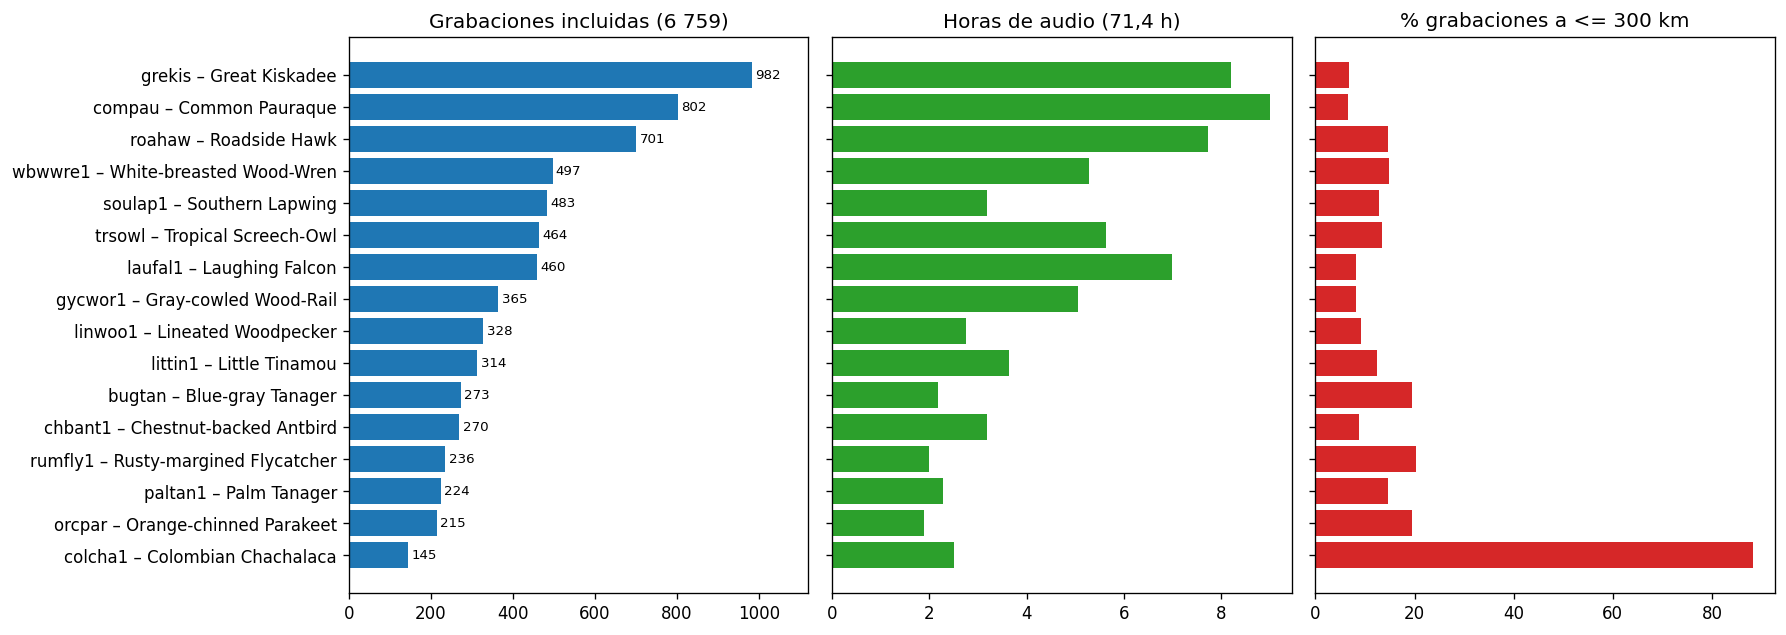

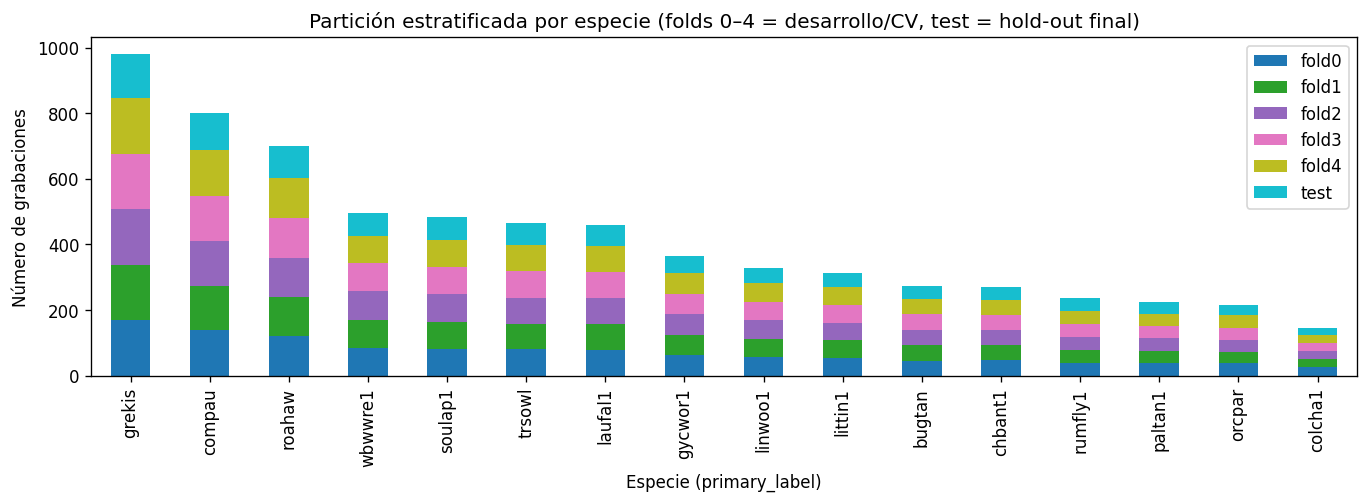

In [18]:
# ==============================================================================
# 7.1 GRÁFICAS DE DISTRIBUCIÓN, HORAS, REGIONALIDAD Y PARTICIONES DEL SUBCONJUNTO
# ==============================================================================
# Ordenar las 16 especies de menor a mayor número de grabaciones incluidas
order = sp_sel.sort_values("n_incl").index
labels = [f"{c} – {sp_sel.loc[c, 'common_name']}" for c in order]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)

# Panel 1: Número de grabaciones incluidas por especie
axes[0].barh(labels, sp_sel.loc[order, "n_incl"], color="tab:blue")
axes[0].set_title("Grabaciones incluidas (6 759)")
for i, v in enumerate(sp_sel.loc[order, "n_incl"]):
    axes[0].text(v + 8, i, f"{v}", va="center", fontsize=8)
axes[0].set_xlim(0, 1120)

# Panel 2: Horas totales de audio por especie
axes[1].barh(labels, sp_sel.loc[order, "hours_incl"], color="tab:green")
axes[1].set_title("Horas de audio (71,4 h)")

# Panel 3: Porcentaje de grabaciones de cada especie tomadas a <= 300 km de El Silencio
pct_reg = sp_sel.loc[order, "n_regional_incl"] / sp_sel.loc[order, "n_incl"] * 100.0
axes[2].barh(labels, pct_reg, color="tab:red")
axes[2].set_title(f"% grabaciones a <= {int(REGION_RADIUS_KM)} km")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_subset_distribution.png", dpi=130)
plt.show()

# Figura de barras apiladas mostrando el tamaño de fold0..fold4 y test en cada especie
fig, ax = plt.subplots(figsize=(11.5, 4.3))
order_desc = sp_sel.sort_values("n_incl", ascending=False).index
sp_sel.loc[order_desc, ["fold0", "fold1", "fold2", "fold3", "fold4", "test"]].plot.bar(stacked=True, ax=ax, colormap="tab10")
ax.set_title("Partición estratificada por especie (folds 0–4 = desarrollo/CV, test = hold-out final)")
ax.set_xlabel("Especie (primary_label)")
ax.set_ylabel("Número de grabaciones")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_split_per_species.png", dpi=130)
plt.show()

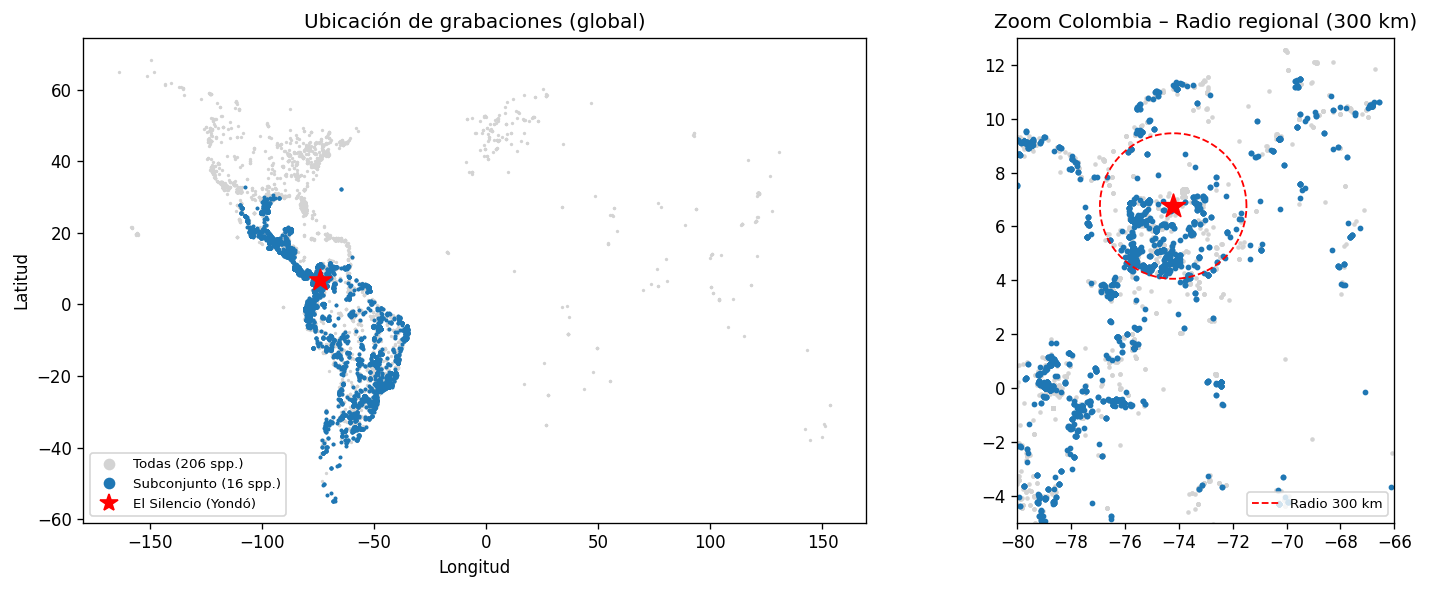

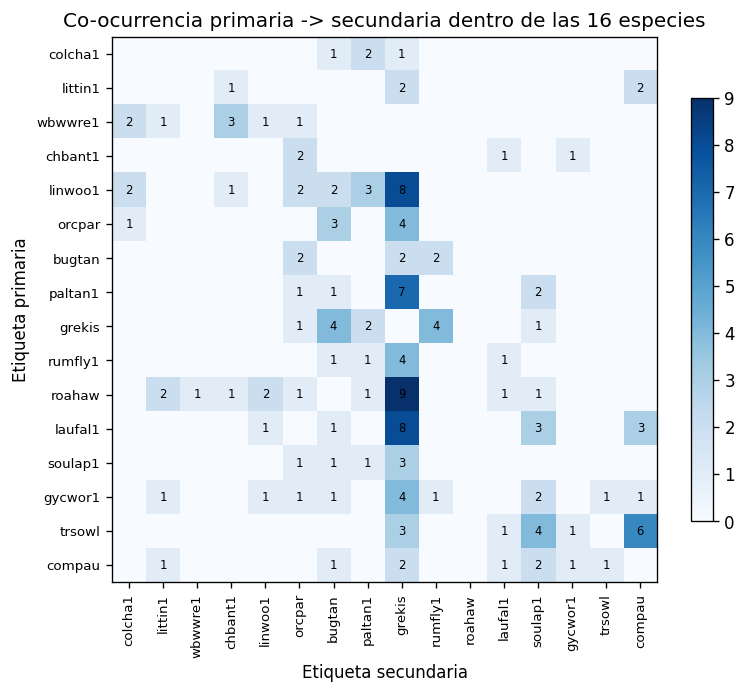

In [19]:
# ==============================================================================
# 7.2 MAPA GEOGRÁFICO (GLOBAL Y ZOOM COLOMBIA) Y MATRIZ DE CO-OCURRENCIA 16x16
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
d_coords = df.dropna(subset=["latitude"])
s_coords = sub.dropna(subset=["latitude"])

# Panel izquierdo: Distribución continental de todas las grabaciones vs subconjunto
axes[0].scatter(d_coords["longitude"], d_coords["latitude"], s=1, c="lightgray")
axes[0].scatter(s_coords["longitude"], s_coords["latitude"], s=2, c="tab:blue")
axes[0].scatter(EL_SILENCIO_LON, EL_SILENCIO_LAT, marker="*", s=180, c="red")
axes[0].set_title("Ubicación de grabaciones (global)")
axes[0].set_xlabel("Longitud")
axes[0].set_ylabel("Latitud")
axes[0].legend(handles=[
    Line2D([], [], marker="o", ls="", color="lightgray", label="Todas (206 spp.)"),
    Line2D([], [], marker="o", ls="", color="tab:blue", label="Subconjunto (16 spp.)"),
    Line2D([], [], marker="*", ls="", color="red", markersize=11, label="El Silencio (Yondó)"),
], fontsize=8, loc="lower left")

# Panel derecho: Zoom a Colombia con círculo de 300 km alrededor de El Silencio
ax = axes[1]
ax.scatter(d_coords["longitude"], d_coords["latitude"], s=3, c="lightgray")
ax.scatter(s_coords["longitude"], s_coords["latitude"], s=6, c="tab:blue")
ax.scatter(EL_SILENCIO_LON, EL_SILENCIO_LAT, marker="*", s=220, c="red")
theta = np.linspace(0, 2 * np.pi, 200)
dlat = REGION_RADIUS_KM / 111.0
dlon = REGION_RADIUS_KM / (111.0 * np.cos(np.radians(EL_SILENCIO_LAT)))
ax.plot(EL_SILENCIO_LON + dlon * np.cos(theta), EL_SILENCIO_LAT + dlat * np.sin(theta), "r--", lw=1.1, label="Radio 300 km")
ax.set_xlim(-80, -66)
ax.set_ylim(-5, 13)
ax.set_aspect("equal")
ax.set_title("Zoom Colombia – Radio regional (300 km)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_map.png", dpi=130)
plt.show()

# Construir la matriz de co-ocurrencia 16x16 (filas = primary_label, columnas = secondary_label)
cooc_matrix = pd.DataFrame(0, index=SUBSET_CODES, columns=SUBSET_CODES)
for p_lab, sec_list in zip(sub["primary_label"], sub["secondary"]):
    for s_lab in sec_list:
        if s_lab in SUBSET_SET:
            cooc_matrix.loc[p_lab, s_lab] += 1
cooc_matrix.to_csv(TABLES_DIR / "subset_cooccurrence.csv")

# Graficar mapa de calor de co-ocurrencias entre las 16 especies
fig, ax = plt.subplots(figsize=(6.8, 5.8))
im = ax.imshow(cooc_matrix.values, cmap="Blues")
ax.set_xticks(range(len(SUBSET_CODES)), SUBSET_CODES, rotation=90, fontsize=8)
ax.set_yticks(range(len(SUBSET_CODES)), SUBSET_CODES, fontsize=8)
for i in range(len(SUBSET_CODES)):
    for j in range(len(SUBSET_CODES)):
        val = cooc_matrix.values[i, j]
        if val > 0:
            ax.text(j, i, str(val), ha="center", va="center", fontsize=7)
ax.set_xlabel("Etiqueta secundaria")
ax.set_ylabel("Etiqueta primaria")
ax.set_title("Co-ocurrencia primaria -> secundaria dentro de las 16 especies")
plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_subset_cooccurrence.png", dpi=130)
plt.show()

---
## 8. Implementación y Prueba de las Métricas del Protocolo de Evaluación

De acuerdo con [`docs/plan_trabajo.md`](../docs/plan_trabajo.md) y [`src/evaluation/metrics.py`](../src/evaluation/metrics.py), el desempeño de todos los modelos supervisados (Baseline en Hito 4/5, SVM lineal/RBF/polinomial en Hito 5, Random Forest y XGBoost en Hito 6) se medirá con:
1. **Macro ROC-AUC (`roc_auc_macro`):** promedio no ponderado del área bajo la curva ROC (One-vs-Rest) de las 16 especies. Es la métrica oficial de BirdCLEF+ 2025 e invariante al umbral de decisión. **Meta experimental del curso: $> 0.75$**.
2. **Macro-F1 (`f1_macro`):** promedio no ponderado del F1-score de las 16 especies, donde una especie minoritaria como `colcha1` (145 grabaciones) pesa exactamente igual que `grekis` (982 grabaciones). **Meta experimental del curso: $> 0.65$**.
3. **Métricas complementarias:** `precision_macro`, `recall_macro`, `balanced_accuracy`, `accuracy` y el vector de **F1 por especie (`per_class_f1`)** para diagnosticar confusiones entre los 4 pares acústicamente similares.

En la celda siguiente definimos la función completa y verificamos su funcionamiento sobre el conjunto `test` (`965` grabaciones) utilizando un predictor aleatorio de referencia (*Dummy Baseline*), comprobando que sin señal acústica el Macro ROC-AUC es $\approx 0.50$ y el Macro-F1 es $\approx \frac{1}{16} = 0.0625$.

In [20]:
# ==============================================================================
# 8. FUNCIÓN DE MÉTRICAS DEL PROTOCOLO Y VERIFICACIÓN CON BASELINE DUMMY EN TEST
# ==============================================================================
def compute_evaluation_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_prob: np.ndarray | None = None,
    class_names: list[str] | None = None,
) -> dict:
    """Calcula Macro ROC-AUC, Macro-F1, precisión, recall, balanced accuracy y F1 por especie."""
    out = {
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_true, y_pred)), 4),
        "f1_macro": round(float(f1_score(y_true, y_pred, average="macro", zero_division=0)), 4),
        "precision_macro": round(float(precision_score(y_true, y_pred, average="macro", zero_division=0)), 4),
        "recall_macro": round(float(recall_score(y_true, y_pred, average="macro", zero_division=0)), 4),
    }
    if y_prob is not None:
        # Macro ROC-AUC One-vs-Rest (cada una de las 16 especies pesa exactamente 1/16)
        out["roc_auc_macro"] = round(
            float(roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")), 4
        )
    if class_names is not None:
        # F1 individual para cada una de las 16 especies
        f1_per_cls = f1_score(y_true, y_pred, labels=class_names, average=None, zero_division=0)
        out["per_class_f1"] = {c: round(float(v), 4) for c, v in zip(class_names, f1_per_cls)}
    return out

# Prueba de sanidad con un clasificador Dummy aleatorio (semilla fija SEED = 42) sobre las 965 grabaciones de test
rng = np.random.default_rng(SEED)
classes_sorted = sorted(SUBSET_CODES)

test_df = sub[sub["split"] == "test"]
y_test_true = test_df["primary_label"].values

# Generar matriz de probabilidades aleatorias (965 x 16) que suman 1 por fila
raw_scores = rng.random((len(test_df), len(classes_sorted)))
y_test_prob = raw_scores / raw_scores.sum(axis=1, keepdims=True)
y_test_pred = np.array([classes_sorted[i] for i in y_test_prob.argmax(axis=1)])

dummy_res = compute_evaluation_metrics(y_test_true, y_test_pred, y_test_prob, class_names=classes_sorted)
print("Resultado de referencia (Dummy aleatorio sin señal acústica en test, n=965):")
print(json.dumps({k: v for k, v in dummy_res.items() if k != "per_class_f1"}, indent=2))

Resultado de referencia (Dummy aleatorio sin señal acústica en test, n=965):
{
  "accuracy": 0.0746,
  "balanced_accuracy": 0.0702,
  "f1_macro": 0.0674,
  "precision_macro": 0.0751,
  "recall_macro": 0.0702,
  "roc_auc_macro": 0.5121
}


---
## 9. Verificación de Sincronización con los Módulos del Repositorio (`src/utils/helpers.py`, `src/data/`, `src/evaluation/`)

Para garantizar que tanto el notebook como los scripts modulares del repositorio (`python src/main.py`) utilicen exactamente las mismas funciones documentadas, importamos a continuación [`src/utils/helpers.py`](../src/utils/helpers.py) y comprobamos que sus resultados coinciden con los generados en este notebook.

In [21]:
# ==============================================================================
# 9. COMPROBACIÓN DE LOS MÓDULOS DE PRODUCCIÓN EN src/utils/helpers.py Y src/data/
# ==============================================================================
from src.utils import helpers as repo_helpers

# Verificar que las funciones documentadas en src/utils/helpers.py producen resultados idénticos
assert abs(repo_helpers.gini_coefficient(sp_sel["n_incl"]) - gini_coefficient(sp_sel["n_incl"])) < 1e-12
assert repo_helpers.parse_list_field("['grekis', '']") == ["grekis"]
assert repo_helpers.parse_soundscape_filename("H02_20230420_074000.ogg") == {
    "site": "H02", "date": "20230420", "time": "074000"
}

print("Módulo src/utils/helpers.py verificado correctamente.")
print("Archivos listos en src/data/processed/:")
for p in sorted(PROCESSED_DIR.glob("*.csv")):
    print(f"  - {p.name:30s} ({p.stat().st_size / 1024:8.1f} KB)")

Módulo src/utils/helpers.py verificado correctamente.
Archivos listos en src/data/processed/:
  - split_all_recordings.csv       (  1510.8 KB)
  - subset_recordings.csv          (  1136.1 KB)
  - subset_species.csv             (     6.8 KB)
  - train_durations.csv            (  1569.2 KB)
  - train_soundscapes_meta.csv     (  1052.8 KB)
